# Import libraries

In [1]:
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import glob
import os
from keras.models import load_model,Model
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import (Dense, BatchNormalization, Reshape, Conv2D, Conv2DTranspose,Input,
                                     LeakyReLU, Dropout, Flatten, MaxPooling2D, GlobalAveragePooling2D,
                                     GlobalMaxPooling2D, SeparableConv2D, Activation, InputLayer,Add,GaussianNoise,RandomRotation,
                                     Lambda,RandomZoom,MaxPool2D,ReLU)
from tensorflow.keras.optimizers import Adam, Adamax, AdamW
from tensorflow.keras.losses import BinaryCrossentropy, CategoricalCrossentropy, SparseCategoricalCrossentropy
from tensorflow.keras.metrics import CategoricalAccuracy, AUC, Precision, Recall
from tensorflow.keras.applications import (Xception, EfficientNetB0, VGG19, ResNet50, ResNet50V2,MobileNetV2,
                                           DenseNet121, InceptionV3, MobileNetV3Small, MobileNetV3Large)
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.applications.efficientnet import preprocess_input as efficientnet_preprocess
from tensorflow.keras.callbacks import (LearningRateScheduler, ReduceLROnPlateau, ModelCheckpoint, EarlyStopping)
from tensorflow.keras.initializers import RandomNormal
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import plot_model, to_categorical
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers.schedules import ExponentialDecay

import shutil

import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.utils import shuffle, class_weight
import cv2

# Split Data

In [2]:
# Function to display images from the dataset
def display_sample_images(df, num_samples,class_name=None):
    plt.figure(figsize=(8, 10))
    plt.title(class_name)
    for i in range(num_samples):
        plt.subplot(4, num_samples, i + 1)
        img = plt.imread(df.iloc[i]['filepaths'])
        plt.imshow(img,cmap=plt.cm.gray)
        plt.axis('off')
    
    plt.tight_layout()
    plt.show()

In [ ]:
def read_split(path,class_name):
    paths = glob.glob(f"{path}/*.jpg")
    df = pd.DataFrame({'filepaths':paths,"label":class_name})
    generate_set, val_set = train_test_split(df, train_size=0.80, random_state=123)
    return generate_set,val_set

In [ ]:
def read(path,class_name):
    paths = glob.glob(f"{path}/*.jpg") + glob.glob(f"{path}/*.png")
    df = pd.DataFrame({'filepaths':paths,"label":class_name})
    return df

In [ ]:
def Image_Data_Generator(df, batch_size=64):
    """
    Generates batches of images with preprocessing and augmentation for DCGAN training.
    """
    # Define ImageDataGenerator for preprocessing and augmentation
    generate_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        preprocessing_function=lambda x: (x / 127.5) - 1.0,  
        # rotation_range=5,
        horizontal_flip=True, 
        # brightness_range=[0.9, 1.1],
        # shear_range=0.05,
        # zoom_range=0.05,
        # width_shift_range=0.01,
        # height_shift_range=0.01,
        fill_mode='nearest'
    )

    # Create data generator from the dataframe
    train_gen = generate_image_gen.flow_from_dataframe(
        dataframe=df,
        x_col="filepaths",
        y_col=None, 
        target_size=(128, 128), 
        color_mode='grayscale', 
        class_mode=None, 
        batch_size=batch_size,
        shuffle=True 
    )
    return train_gen


In [76]:
from typing import Tuple
import tensorflow as tf
import pandas as pd

def Image_Data_Generator_for_cnn(df_train, df_val, batch_size):

    # Image augmentation for training
    train_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1.0 / 255.0,
        rotation_range=20,
        # width_shift_range=0.02,
        # height_shift_range=0.02,
        # # shear_range=0.0,
        # zoom_range=0.05,
        horizontal_flip=True,
        # fill_mode='nearest',
        # brightness_range=[0.9, 1.1]
    )
    train_gen = train_image_gen.flow_from_dataframe(
        dataframe=df_train,
        x_col="filepaths",
        y_col="label",
        target_size=(128, 128),  # Fixed dimensions to match model input
        color_mode='grayscale',
        class_mode="categorical",
        batch_size=batch_size,
        shuffle=True,
    )
    
    # Validation data preprocessing
    val_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
        rescale=1.0 / 255.0
    )
    val_gen = val_image_gen.flow_from_dataframe(
        dataframe=df_val,
        x_col="filepaths",
        y_col="label",
        target_size=(128, 128),  # Fixed dimensions to match model input
        color_mode='grayscale',
        class_mode="categorical",
        batch_size=batch_size,
        shuffle=False
    )
    
    return train_gen, val_gen


In [ ]:
def dispaly_image_generator(sample_images):
    plt.figure(figsize=(12, 12))
    for i in range(16):
        ax = plt.subplot(4, 4, i + 1)
        plt.imshow((sample_images[i] * 127.5 + 127.5).astype(np.uint8),cmap = 'gray')
        plt.axis("off")
    plt.show()

In [ ]:
def plot_metrics(history):
    # Create a figure to hold the plots
    plt.figure(figsize=(12, 6))
    
    # Plot Accuracy
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Val Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # Plot Loss
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Val Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()


    plt.tight_layout()  # Adjust subplots to fit into the figure area.
    plt.show()

In [ ]:
def train_DCGAN(train_gen,ask_epoch, freq=500, batch_size=64, EPOCHS=10000):
    IMG_SHAPE = (128, 128, 1)
    LATENT_DIM = 400
    GRADIENT_PENALTY_WEIGHT = 10.0

    # ResNet Block for Generator
    def ResNetBlock(input_tensor, filters):
        x = Conv2DTranspose(filters, (4, 4), strides=(1, 1), padding='same')(input_tensor)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = Conv2DTranspose(filters, (4, 4), strides=(1, 1), padding='same')(x)
        x = BatchNormalization()(x)
        x = Add()([input_tensor, x])
        return LeakyReLU(alpha=0.2)(x)

    # Generator Model
    def Generator_Model():
        inputs = Input(shape=(LATENT_DIM,))
        
        x = Dense(8 * 8 * 512)(inputs)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = Reshape((8, 8, 512))(x)
        # x = GaussianNoise(0.05)(x)

        # x = Conv2DTranspose(512, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        # x = BatchNormalization()(x)
        # x = LeakyReLU(alpha=0.2)(x)
        # x = ResNetBlock(x, 512)

        x = Conv2DTranspose(256, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = ResNetBlock(x, 256)

        x = Conv2DTranspose(128, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = GaussianNoise(0.2)(x)
        # x = Dropout(0.2)(x)

        x = Conv2DTranspose(64, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = GaussianNoise(0.2)(x)
        # x = Dropout(0.2)(x)

        x = Conv2DTranspose(32, (4, 4), strides=(2, 2), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        # x = Dropout(0.2)(x)

        outputs = Conv2DTranspose(1, (3, 3), padding='same', activation='tanh')(x)
        return Model(inputs, outputs)

    # Discriminator Model
    def Discriminator_Model():
        inputs = Input(shape=IMG_SHAPE)

        
        x = Conv2D(64, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(inputs)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        # x = Dropout(0.2)(x)
        # x = GaussianNoise(0.1)(x)
        
        x = Conv2D(128, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        # x = GaussianNoise(0.1)(x)
        # x = Dropout(0.2)(x)
        
        x = Conv2D(256, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        x = Dropout(0.1)(x)

        x = Conv2D(512, (3, 3), padding='same',kernel_regularizer=l2(0.0001))(x)
        x = BatchNormalization()(x)
        x = LeakyReLU(alpha=0.2)(x)
        x = MaxPooling2D(pool_size=(2, 2))(x)
        x = Dropout(0.1)(x)

        x = GlobalAveragePooling2D()(x)
        outputs = Dense(1)(x)  # No activation for WGAN-GP
        return Model(inputs, outputs)

    # Gradient Penalty Function
    def gradient_penalty(discriminator, real_images, fake_images):
        batch_size = tf.shape(real_images)[0]
        alpha = tf.random.uniform([batch_size, 1, 1, 1], 0.0, 1.0)
        interpolated = alpha * real_images + (1 - alpha) * fake_images
        with tf.GradientTape() as tape:
            tape.watch(interpolated)
            predictions = discriminator(interpolated, training=True)
        gradients = tape.gradient(predictions, [interpolated])[0]
        gradients_norm = tf.sqrt(tf.reduce_sum(tf.square(gradients), axis=[1, 2, 3]))
        penalty = tf.reduce_mean((gradients_norm - 1.0) ** 2)
        return penalty

    # DCGAN Model with Gradient Penalty
    class DCGAN(tf.keras.Model):
        def __init__(self, generator, discriminator, latent_dim=LATENT_DIM):
            super(DCGAN, self).__init__()
            self.generator = generator
            self.discriminator = discriminator
            self.latent_dim = latent_dim

        def compile(self, g_optimizer, d_optimizer, loss_fn):
            super(DCGAN, self).compile()
            self.g_optimizer = g_optimizer
            self.d_optimizer = d_optimizer
            self.loss_fn = loss_fn

        def train_step(self, data):
            real_images = tf.reshape(data, (-1,) + IMG_SHAPE)
            batch_size = tf.shape(real_images)[0]
            random_noise = tf.random.normal(shape=(batch_size, self.latent_dim))

            # Train Discriminator
            with tf.GradientTape() as tape:
                fake_images = self.generator(random_noise, training=True)
                pred_real = self.discriminator(real_images, training=True)
                pred_fake = self.discriminator(fake_images, training=True)
                gp = gradient_penalty(self.discriminator, real_images, fake_images)
                d_loss = tf.reduce_mean(pred_fake) - tf.reduce_mean(pred_real) + GRADIENT_PENALTY_WEIGHT * gp
            gradients = tape.gradient(d_loss, self.discriminator.trainable_variables)
            self.d_optimizer.apply_gradients(zip(gradients, self.discriminator.trainable_variables))

            # Train Generator
            with tf.GradientTape() as tape:
                fake_images = self.generator(random_noise, training=True)
                pred_fake = self.discriminator(fake_images, training=True)
                g_loss = -tf.reduce_mean(pred_fake)
            gradients = tape.gradient(g_loss, self.generator.trainable_variables)
            self.g_optimizer.apply_gradients(zip(gradients, self.generator.trainable_variables))

            return {'d_loss': d_loss, 'g_loss': g_loss}

    class UserPromptCallback(tf.keras.callbacks.Callback):
        def __init__(self, prompt_frequency):
            super(UserPromptCallback, self).__init__()
            self.prompt_frequency = prompt_frequency
            self.remaining_epochs = prompt_frequency

        def on_epoch_end(self, epoch, logs=None):
            self.remaining_epochs -= 1
            if self.remaining_epochs <= 0:
                response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
                if response == 'stop':
                    print("Stopping training as requested by the user.")
                    self.model.stop_training = True
                elif response == 'add':
                    additional_epochs = int(input("How many more epochs to add? ").strip())
                    print(f"Added {additional_epochs} more epochs.")
                    self.remaining_epochs = additional_epochs

    # Image Display Callback
    class ImageDisplayCallback(tf.keras.callbacks.Callback):
        def __init__(self, generator, display_frequency=freq, latent_dim=LATENT_DIM, num_images=10):
            super(ImageDisplayCallback, self).__init__()
            self.generator = generator
            self.display_frequency = display_frequency
            self.latent_dim = latent_dim
            self.num_images = num_images

        def on_epoch_end(self, epoch, logs=None):
            if (epoch + 1) % self.display_frequency == 0:
                self.display_images()

        def display_images(self):
            random_latent_vectors = tf.random.normal([self.num_images, self.latent_dim])
            generated_images = self.generator(random_latent_vectors, training=False)
            generated_images = (generated_images + 1) / 2.0  # Scale to [0, 1]

            plt.figure(figsize=(10, 5))
            for i in range(self.num_images):
                plt.subplot(2, 5, i + 1)
                plt.imshow(tf.squeeze(generated_images[i]), cmap="gray")
                plt.axis("off")
            plt.show()

    # Instantiate Models
    generator = Generator_Model()
    discriminator = Discriminator_Model()
    dcgan = DCGAN(generator=generator, discriminator=discriminator)

    # Optimizers and Compile
    generator_optimizer = Adam(learning_rate=0.0005, beta_1=0.5)
    discriminator_optimizer = Adam(learning_rate=0.0004, beta_1=0.5)
    dcgan.compile(
        g_optimizer=generator_optimizer,
        d_optimizer=discriminator_optimizer,
        loss_fn=BinaryCrossentropy(from_logits=True)
    )

    # Callbacks
    reduce_lr_g = ReduceLROnPlateau(monitor='g_loss', factor=0.2, patience=int(EPOCHS * 0.40), verbose=1, min_lr=1e-6)
    reduce_lr_d = ReduceLROnPlateau(monitor='d_loss', factor=0.2, patience=int(EPOCHS * 0.40), verbose=1, min_lr=1e-6)
    image_display_callback = ImageDisplayCallback(generator=generator, display_frequency=freq)
    user_prompt_callback = UserPromptCallback(prompt_frequency=ask_epoch)

    # Train the DCGAN
    history = dcgan.fit(
        train_gen,
        epochs=EPOCHS,
        batch_size=batch_size,
        callbacks=[ image_display_callback,user_prompt_callback]
    )
    return dcgan


In [ ]:
import tensorflow as tf
import os
from PIL import Image

def generate_and_save_images(generator, subfolder_name, num_images=10000, latent_dim=400, batch_size=128):
    # Create the main directory 'generated_image'
    output_dir = "Dataset"
    os.makedirs(output_dir, exist_ok=True)
    
    # Create the user-specified subfolder inside 'generated_image'
    subfolder = os.path.join(output_dir, subfolder_name)
    os.makedirs(subfolder, exist_ok=True)

    num_batches = num_images // batch_size
    remaining_images = num_images % batch_size

    image_count = 0

    # Generate images in batches
    for batch in range(num_batches):
        # Generate random latent vectors for the batch
        random_latent_vectors = tf.random.normal([batch_size, latent_dim])
        
        # Generate images using the trained Generator
        generated_images = generator(random_latent_vectors, training=False)
        
        # Scale images from [-1, 1] to [0, 255] for saving
        generated_images = (generated_images + 1) * 127.5
        generated_images = tf.clip_by_value(generated_images, 0, 255)
        generated_images = tf.cast(generated_images, tf.uint8)

        # Save each generated image with the subfolder name and image number
        for i in range(batch_size):
            img_array = generated_images[i].numpy()
            img = Image.fromarray(img_array.squeeze(), mode="L")  # Assuming grayscale
            img.save(os.path.join(subfolder, f"{subfolder_name}_{image_count + 1}.png"))  # Using subfolder name and number
            image_count += 1
            
        tf.keras.backend.clear_session()  # Clearing session after each batch (optional)

    # Handle remaining images (if any) in a smaller batch
    if remaining_images > 0:
        random_latent_vectors = tf.random.normal([remaining_images, latent_dim])
        generated_images = generator(random_latent_vectors, training=False)
        generated_images = (generated_images + 1) * 127.5
        generated_images = tf.clip_by_value(generated_images, 0, 255)
        generated_images = tf.cast(generated_images, tf.uint8)

        for i in range(remaining_images):
            img_array = generated_images[i].numpy()
            img = Image.fromarray(img_array.squeeze(), mode="L")
            img.save(os.path.join(subfolder, f"{subfolder_name}_{image_count + 1}.png"))
            image_count += 1
        tf.keras.backend.clear_session()  # Clearing session after the remaining batch (optional)

    print(f"{num_images} images saved in '{subfolder}' directory.")



In [ ]:
Moderate_Demented_path = r'/kaggle/input/alzheimer/Dataset/Moderate_Demented'
Moderate_generate_set,Moderate_val_set = read_split(Moderate_Demented_path,"Moderate_Demented")
display_sample_images(Moderate_generate_set, num_samples=4,class_name = "Moderate_Demented")

In [ ]:
Mild_Demented_path = r'/kaggle/input/alzheimer/Dataset/Mild_Demented'
Mild_generate_set,Mild_val_set = read_split(Mild_Demented_path,"Mild_Demented")
display_sample_images(Mild_generate_set, num_samples=4,class_name = "Mild_Demented")

In [ ]:
Very_Mild_Demented_path = r'/kaggle/input/alzheimer/Dataset/Very_Mild_Demented'
Very_Mild_generate_set,Very_Mild_val_set = read_split(Very_Mild_Demented_path,"Very_Mild_Demented")
display_sample_images(Very_Mild_generate_set, num_samples=4,class_name = "Very_Mild_Demented")

In [ ]:
Non_Demented_path = r'/kaggle/input/alzheimer/Dataset/Non_Demented'
Non_generate_set,Non_val_set = read_split(Non_Demented_path,"Non_Demented")
display_sample_images(Non_generate_set, num_samples=4,class_name = "Non_Demented")

Found 51 validated image filenames.


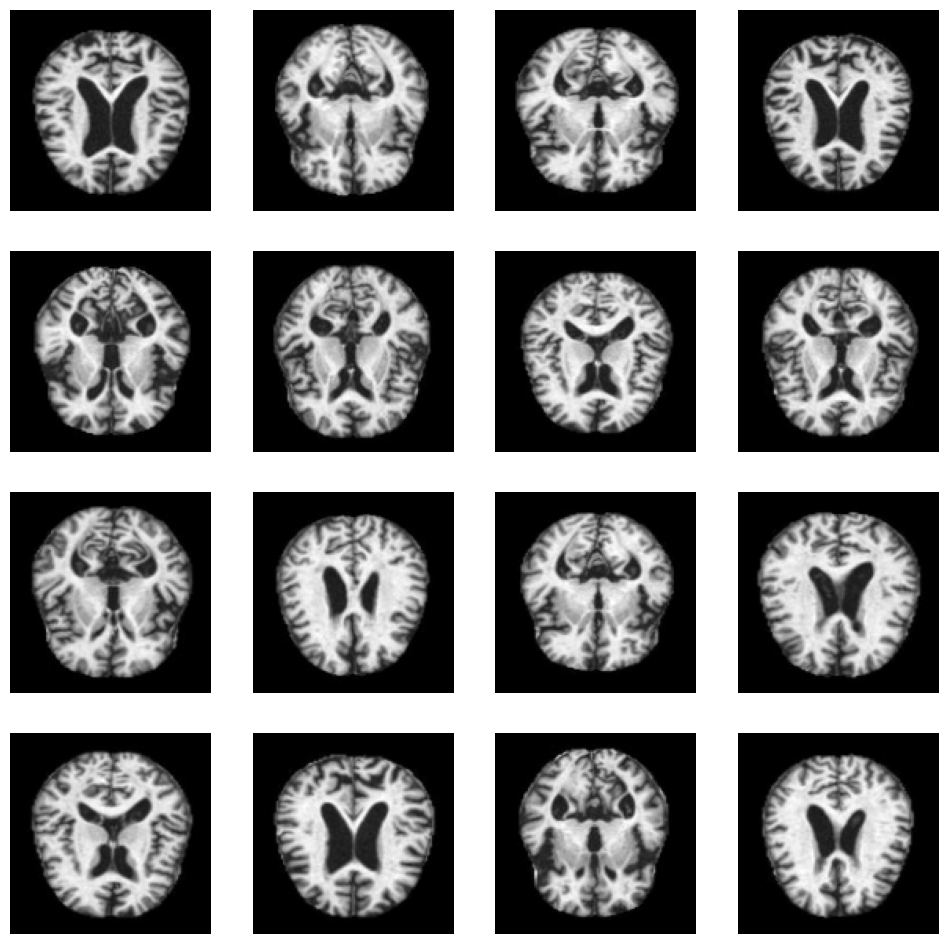

In [22]:
Moderate_train_gen = Image_Data_Generator(Moderate_generate_set,batch_size = 51)
sample_images = next(Moderate_train_gen)
dispaly_image_generator(sample_images)

Epoch 1/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 30s 30s/step - d_loss: 2.3632 - g_loss: -2.3743
Epoch 2/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step - d_loss: 0.6320 - g_loss: -2.2318
Epoch 3/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 551ms/step - d_loss: -0.0660 - g_loss: -1.8584
Epoch 4/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 552ms/step - d_loss: -1.2883 - g_loss: -1.5605
Epoch 5/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step - d_loss: -2.1950 - g_loss: -1.4578
Epoch 6/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 551ms/step - d_loss: -3.3205 - g_loss: -0.9235
Epoch 7/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 622ms/step - d_loss: -4.1444 - g_loss: -0.9411
Epoch 8/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step - d_loss: -4.1789 - g_loss: -0.2063
Epoch 9/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 681ms/step - d_loss: -4.2537 - g_loss: -0.7257
Epoch 10/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 558ms/step - d_loss: -4.8076 - g_loss: -0.5415
Epoch 11/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 557ms/step - d_loss: -5.6576 - g_loss: -0.2308
Epoch 12/3000
1/1 ━━━━━━━━━━━━━━━

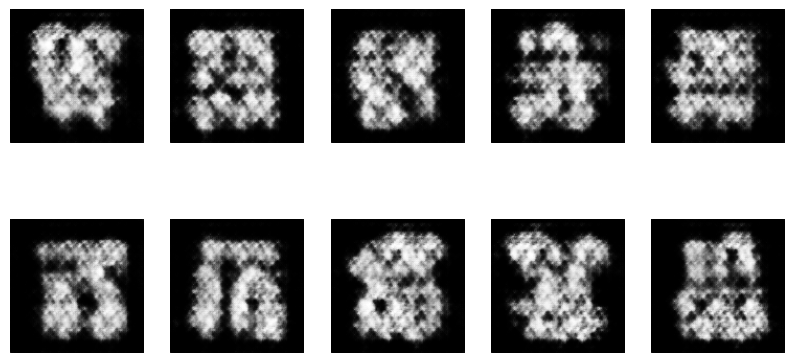

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 950ms/step - d_loss: -4.6070 - g_loss: -7.1344
Epoch 201/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step - d_loss: -4.6550 - g_loss: -6.8008
Epoch 202/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step - d_loss: -4.0801 - g_loss: -5.0620
Epoch 203/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 574ms/step - d_loss: -5.0291 - g_loss: -4.4018
Epoch 204/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step - d_loss: -4.5573 - g_loss: -7.4541
Epoch 205/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step - d_loss: -4.8632 - g_loss: -7.2830
Epoch 206/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step - d_loss: -4.8182 - g_loss: -6.7823
Epoch 207/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 607ms/step - d_loss: -4.2177 - g_loss: -5.5547
Epoch 208/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 623ms/step - d_loss: -4.8618 - g_loss: -4.3359
Epoch 209/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step - d_loss: -4.7512 - g_loss: -5.9298
Epoch 210/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 581ms/step - d_loss: -4.7882 - g_loss: -6.8766
Epoch 211/3000
1/1 ━━━━━━

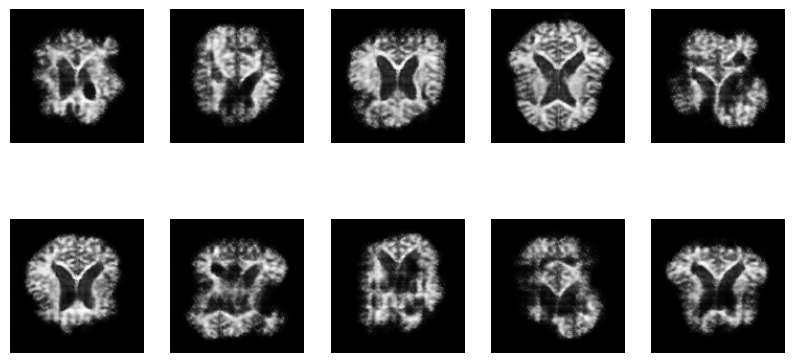

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 945ms/step - d_loss: -4.3950 - g_loss: -7.5853
Epoch 401/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step - d_loss: -3.8779 - g_loss: -7.2066
Epoch 402/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step - d_loss: -3.9963 - g_loss: -6.7108
Epoch 403/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step - d_loss: -4.1106 - g_loss: -7.1489
Epoch 404/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step - d_loss: -4.0772 - g_loss: -7.5527
Epoch 405/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step - d_loss: -3.9166 - g_loss: -6.3982
Epoch 406/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step - d_loss: -4.3714 - g_loss: -5.8993
Epoch 407/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step - d_loss: -4.0853 - g_loss: -6.4059
Epoch 408/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 579ms/step - d_loss: -4.1245 - g_loss: -6.4787
Epoch 409/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 578ms/step - d_loss: -4.2090 - g_loss: -8.0543
Epoch 410/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 574ms/step - d_loss: -4.5939 - g_loss: -5.6512
Epoch 411/3000
1/1 ━━━━━━

Epoch 500 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  300


Added 300 more epochs.
1/1 ━━━━━━━━━━━━━━━━━━━━ 218s 218s/step - d_loss: -2.5066 - g_loss: -7.2845
Epoch 501/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 616ms/step - d_loss: -2.9131 - g_loss: -6.1850
Epoch 502/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 553ms/step - d_loss: -2.5330 - g_loss: -6.4049
Epoch 503/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 554ms/step - d_loss: -3.0459 - g_loss: -5.4212
Epoch 504/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 563ms/step - d_loss: -2.6500 - g_loss: -6.2716
Epoch 505/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step - d_loss: -2.6625 - g_loss: -6.1006
Epoch 506/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 572ms/step - d_loss: -2.8839 - g_loss: -6.8319
Epoch 507/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 577ms/step - d_loss: -2.6826 - g_loss: -7.1451
Epoch 508/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 570ms/step - d_loss: -2.4207 - g_loss: -7.8719
Epoch 509/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 583ms/step - d_loss: -2.7604 - g_loss: -7.2511
Epoch 510/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step - d_loss: -2.5389 - g_loss: -7.0904
E

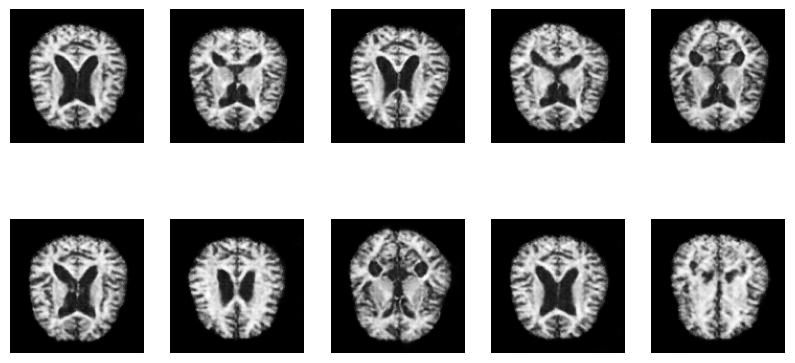

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 990ms/step - d_loss: -1.3569 - g_loss: -5.6072
Epoch 601/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 613ms/step - d_loss: -1.6354 - g_loss: -5.6907
Epoch 602/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 596ms/step - d_loss: -1.2910 - g_loss: -5.8628
Epoch 603/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 592ms/step - d_loss: -1.6694 - g_loss: -5.6492
Epoch 604/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 589ms/step - d_loss: -1.8124 - g_loss: -6.8538
Epoch 605/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 590ms/step - d_loss: -1.7558 - g_loss: -6.4346
Epoch 606/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 584ms/step - d_loss: -1.4529 - g_loss: -6.0488
Epoch 607/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step - d_loss: -1.6856 - g_loss: -5.1547
Epoch 608/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 582ms/step - d_loss: -1.5030 - g_loss: -5.2595
Epoch 609/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 587ms/step - d_loss: -1.2363 - g_loss: -6.0305
Epoch 610/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 593ms/step - d_loss: -1.6513 - g_loss: -7.2620
Epoch 611/3000
1/1 ━━━━━━

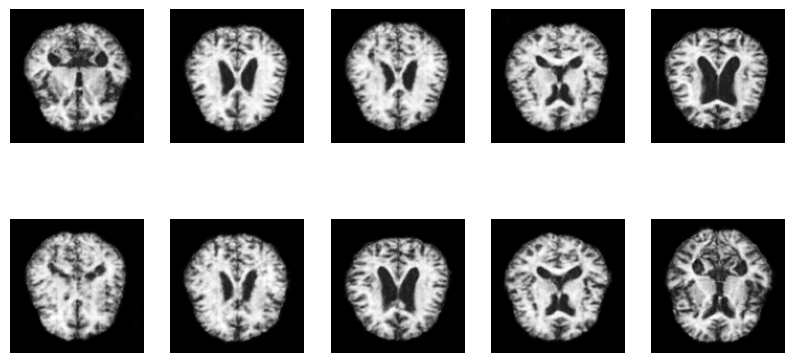

Epoch 800 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  200


Added 200 more epochs.
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step - d_loss: -2.6500 - g_loss: -3.4496 
Epoch 801/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 631ms/step - d_loss: -2.3313 - g_loss: -3.5683
Epoch 802/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 573ms/step - d_loss: -2.5739 - g_loss: -3.5762
Epoch 803/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 575ms/step - d_loss: -2.4621 - g_loss: -3.8393
Epoch 804/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 784ms/step - d_loss: -2.3512 - g_loss: -3.8091
Epoch 805/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 570ms/step - d_loss: -2.2646 - g_loss: -3.9186
Epoch 806/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step - d_loss: -2.4953 - g_loss: -3.9816
Epoch 807/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 567ms/step - d_loss: -2.3779 - g_loss: -4.2283
Epoch 808/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 570ms/step - d_loss: -2.4469 - g_loss: -3.9890
Epoch 809/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 585ms/step - d_loss: -2.5494 - g_loss: -3.5500
Epoch 810/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 578ms/step - d_loss: -2.4644 - g_loss: -3.5691
Ep

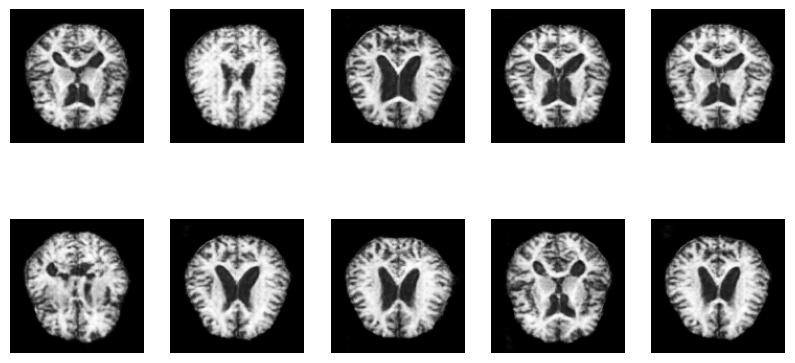

Epoch 1000 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  200


Added 200 more epochs.
1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step - d_loss: -2.6657 - g_loss: -1.1347 
Epoch 1001/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 649ms/step - d_loss: -3.0058 - g_loss: -2.0452
Epoch 1002/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step - d_loss: -2.8333 - g_loss: 0.5569
Epoch 1003/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 567ms/step - d_loss: -2.4307 - g_loss: -0.2254
Epoch 1004/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 566ms/step - d_loss: -3.1025 - g_loss: 1.6576
Epoch 1005/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 738ms/step - d_loss: -2.2052 - g_loss: 0.2685
Epoch 1006/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step - d_loss: -2.0951 - g_loss: 1.7901
Epoch 1007/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 597ms/step - d_loss: -2.8967 - g_loss: 2.2520
Epoch 1008/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 565ms/step - d_loss: -2.0523 - g_loss: 0.9932
Epoch 1009/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step - d_loss: -2.3818 - g_loss: 0.3581
Epoch 1010/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 572ms/step - d_loss: -3.0292 - g_loss: -0.5001

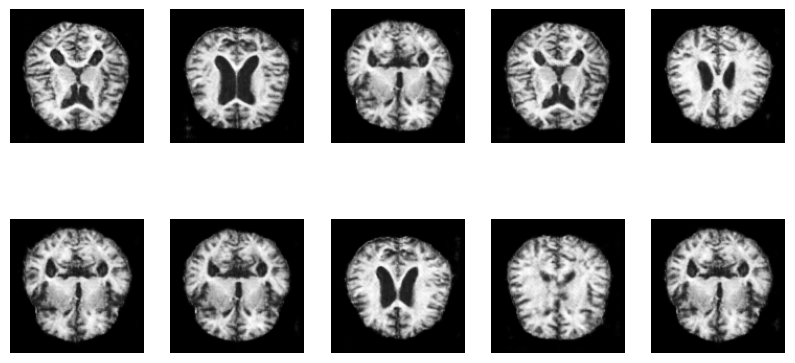

Epoch 1200 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  200


Added 200 more epochs.
1/1 ━━━━━━━━━━━━━━━━━━━━ 95s 95s/step - d_loss: -3.3020 - g_loss: 2.4483 
Epoch 1201/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 610ms/step - d_loss: -3.3870 - g_loss: 2.0717
Epoch 1202/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 565ms/step - d_loss: -3.7515 - g_loss: 1.7662
Epoch 1203/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 555ms/step - d_loss: -3.2418 - g_loss: 4.6942
Epoch 1204/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 569ms/step - d_loss: -3.1788 - g_loss: 3.8287
Epoch 1205/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 564ms/step - d_loss: -3.3760 - g_loss: 4.0691
Epoch 1206/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 564ms/step - d_loss: -2.9095 - g_loss: 3.3810
Epoch 1207/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 563ms/step - d_loss: -3.2445 - g_loss: 2.3102
Epoch 1208/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 562ms/step - d_loss: -3.3119 - g_loss: 1.6639
Epoch 1209/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 576ms/step - d_loss: -3.2019 - g_loss: 3.0734
Epoch 1210/3000
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 559ms/step - d_loss: -3.3757 - g_loss: 3.5041
Epo

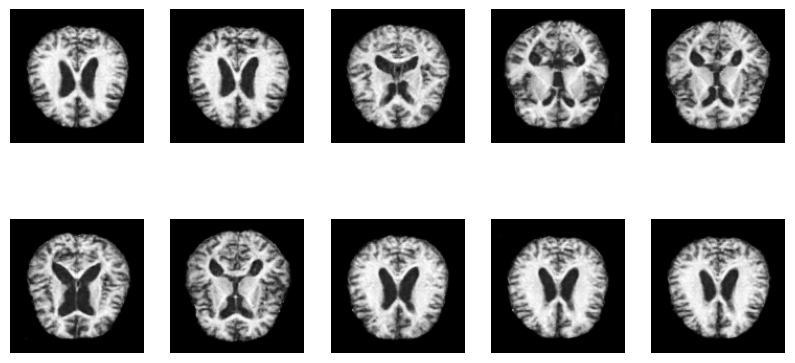

Epoch 1400 completed. Do you want to stop training or add more epochs? (stop/add):  stop


Stopping training as requested by the user.
1/1 ━━━━━━━━━━━━━━━━━━━━ 57s 57s/step - d_loss: -4.0938 - g_loss: 8.0942 


In [25]:
Moderate_model = train_DCGAN(Moderate_train_gen,ask_epoch=500,freq = 200,EPOCHS = 3000,batch_size = 51)

Found 716 validated image filenames.


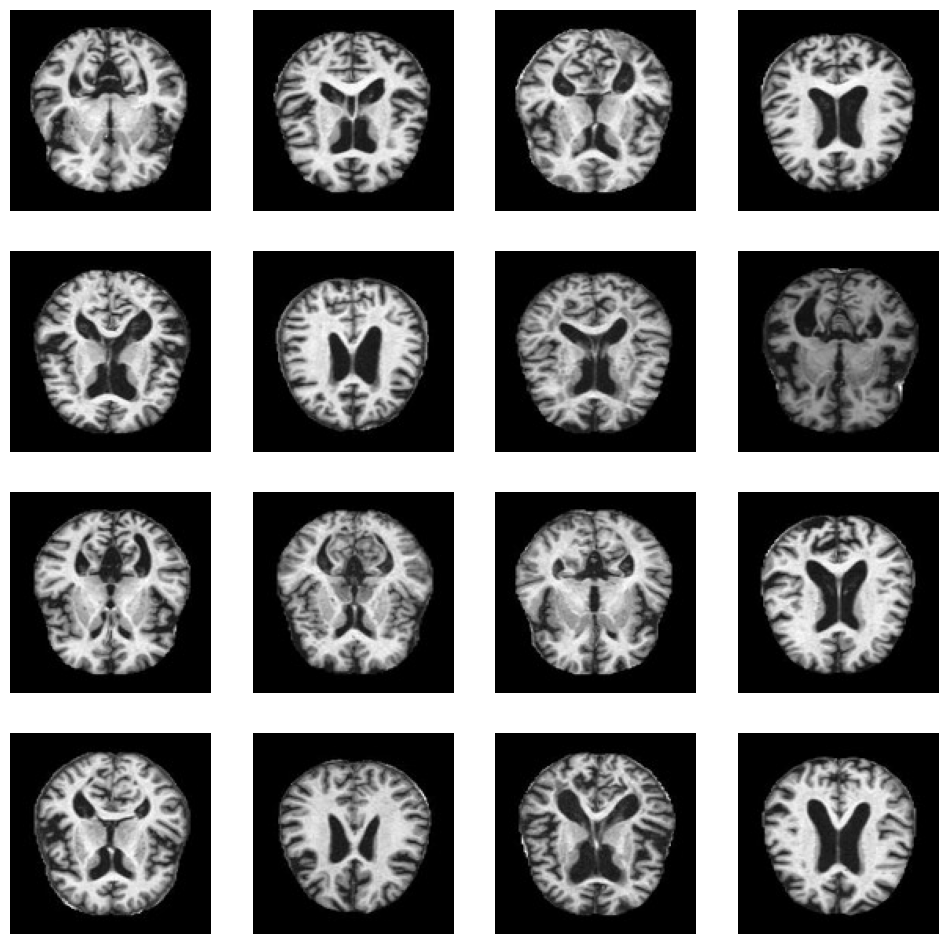

In [26]:
Mild_train_gen = Image_Data_Generator(Mild_generate_set,batch_size = 64)
sample_images = next(Mild_train_gen)
dispaly_image_generator(sample_images)

Epoch 1/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 94s 5s/step - d_loss: -3.6096 - g_loss: 2.1923
Epoch 2/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 539ms/step - d_loss: -9.0469 - g_loss: 4.9734
Epoch 3/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 544ms/step - d_loss: -12.4454 - g_loss: 7.5472
Epoch 4/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 545ms/step - d_loss: -15.6445 - g_loss: 7.6594
Epoch 5/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 539ms/step - d_loss: -19.6370 - g_loss: 8.7200
Epoch 6/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -20.8522 - g_loss: 8.5195
Epoch 7/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step - d_loss: -23.0433 - g_loss: 9.4891
Epoch 8/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 527ms/step - d_loss: -20.6612 - g_loss: 7.8186
Epoch 9/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 526ms/step - d_loss: -9.6818 - g_loss: -0.6214
Epoch 10/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step - d_loss: -10.0420 - g_loss: 0.5499
Epoch 11/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 531ms/step - d_loss: -11.5716 - g_loss: 2.5317
Epoch 12/352
12/12 ━━━━

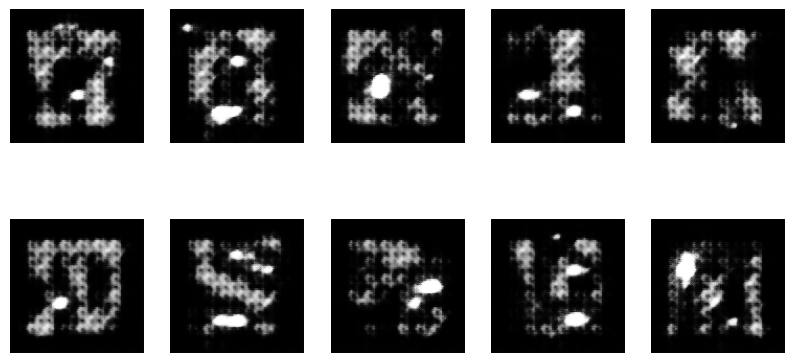

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 562ms/step - d_loss: -6.2462 - g_loss: -3.0286
Epoch 17/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -4.3125 - g_loss: -4.3815
Epoch 18/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -3.1445 - g_loss: -5.7491
Epoch 19/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -3.7202 - g_loss: -5.2537
Epoch 20/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -3.9416 - g_loss: -4.5018
Epoch 21/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -4.3731 - g_loss: -4.3449
Epoch 22/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -4.1550 - g_loss: -3.9280
Epoch 23/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -3.9954 - g_loss: -4.9979
Epoch 24/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -4.0152 - g_loss: -4.5420
Epoch 25/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -3.9865 - g_loss: -4.7102
Epoch 26/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 575ms/step - d_loss: -4.2027 - g_loss: -4.8812
Epoch 27/352
12/12 ━━━━

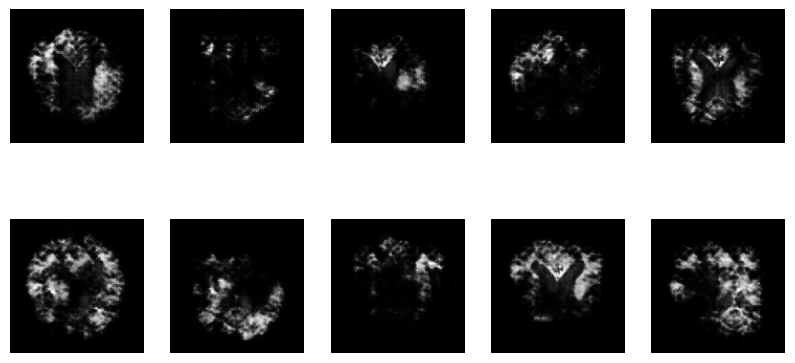

Epoch 32 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  64


Added 64 more epochs.
12/12 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - d_loss: -2.8865 - g_loss: -5.4578  
Epoch 33/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 525ms/step - d_loss: -2.8412 - g_loss: -4.8420
Epoch 34/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -2.3946 - g_loss: -5.8168
Epoch 35/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 543ms/step - d_loss: -2.3322 - g_loss: -5.3945
Epoch 36/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 552ms/step - d_loss: -2.2072 - g_loss: -4.8231
Epoch 37/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 548ms/step - d_loss: -1.7479 - g_loss: -4.1732
Epoch 38/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 541ms/step - d_loss: -1.7972 - g_loss: -5.6800
Epoch 39/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -1.8058 - g_loss: -5.1127
Epoch 40/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.5100 - g_loss: -4.6870
Epoch 41/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step - d_loss: -1.5138 - g_loss: -4.4931
Epoch 42/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - d_loss: -1.4268 - g_loss: -4.9438
E

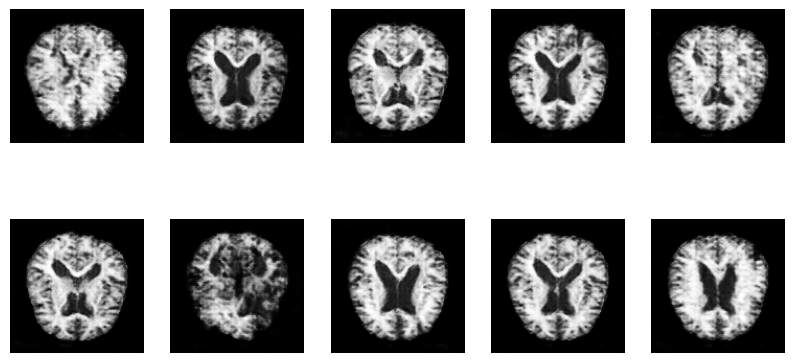

12/12 ━━━━━━━━━━━━━━━━━━━━ 8s 575ms/step - d_loss: -0.9598 - g_loss: -3.4791
Epoch 49/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.8737 - g_loss: -3.0265
Epoch 50/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.8306 - g_loss: -3.3965
Epoch 51/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 576ms/step - d_loss: -0.8110 - g_loss: -2.8118
Epoch 52/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.6392 - g_loss: -2.6116
Epoch 53/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 537ms/step - d_loss: -0.6038 - g_loss: -3.5407
Epoch 54/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.5835 - g_loss: -2.5368
Epoch 55/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.5946 - g_loss: -2.5707
Epoch 56/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.7351 - g_loss: -2.2361
Epoch 57/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -0.6713 - g_loss: -2.3185
Epoch 58/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 537ms/step - d_loss: -0.7085 - g_loss: -2.9768
Epoch 59/352
12/12 ━━━━

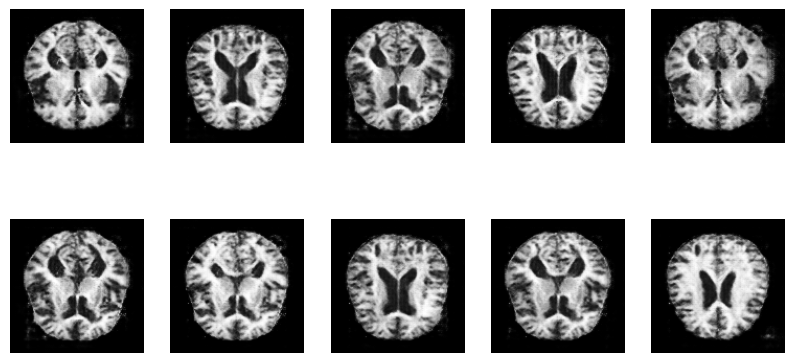

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 564ms/step - d_loss: -0.7804 - g_loss: -1.8837
Epoch 65/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -0.7304 - g_loss: -2.0639
Epoch 66/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -0.7685 - g_loss: -1.6416
Epoch 67/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.8575 - g_loss: -2.0007
Epoch 68/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.7351 - g_loss: -2.6031
Epoch 69/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 574ms/step - d_loss: -0.7191 - g_loss: -2.6269
Epoch 70/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.8424 - g_loss: -1.3718
Epoch 71/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.9309 - g_loss: -1.6668
Epoch 72/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.9421 - g_loss: -1.3694
Epoch 73/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.8569 - g_loss: -1.6669
Epoch 74/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.7849 - g_loss: -1.4330
Epoch 75/352
12/12 ━━━━

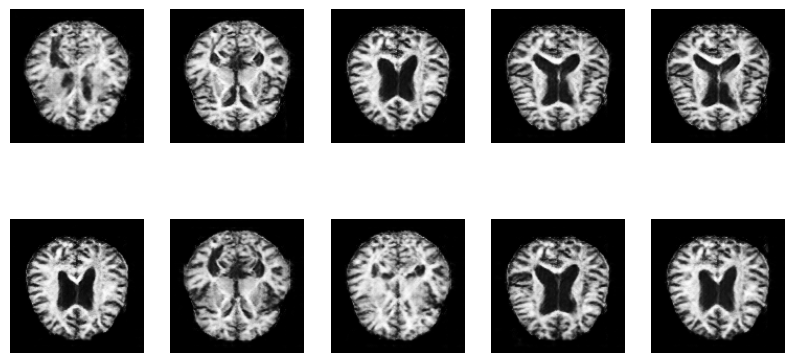

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 564ms/step - d_loss: -0.9139 - g_loss: -0.0120
Epoch 81/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 576ms/step - d_loss: -0.9635 - g_loss: -0.4490
Epoch 82/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 537ms/step - d_loss: -1.0040 - g_loss: -0.3778
Epoch 83/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.9904 - g_loss: -0.5256
Epoch 84/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.0214 - g_loss: -0.2852
Epoch 85/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.0449 - g_loss: -0.0446
Epoch 86/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -1.0116 - g_loss: 0.2391
Epoch 87/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -1.0008 - g_loss: -0.4372
Epoch 88/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -0.9343 - g_loss: -0.2957
Epoch 89/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.9397 - g_loss: -0.1436
Epoch 90/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -0.9331 - g_loss: 0.1774
Epoch 91/352
12/12 ━━━━━━

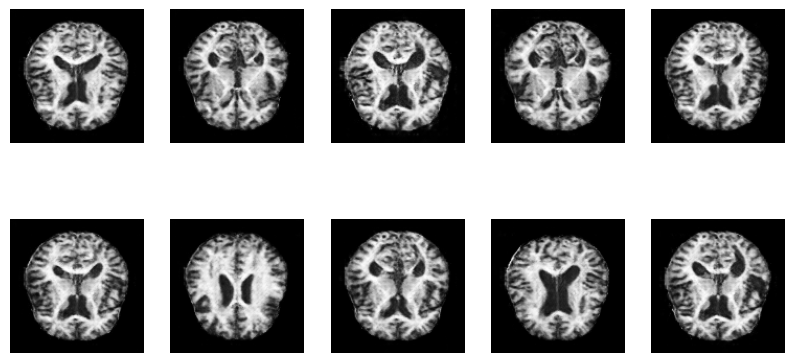

Epoch 96 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  32


Added 32 more epochs.
12/12 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - d_loss: -1.1286 - g_loss: 0.6041  
Epoch 97/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 525ms/step - d_loss: -1.1788 - g_loss: 0.5917
Epoch 98/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -1.0793 - g_loss: 0.3330
Epoch 99/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 542ms/step - d_loss: -1.0779 - g_loss: 1.1374
Epoch 100/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 595ms/step - d_loss: -1.1694 - g_loss: 1.3963
Epoch 101/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 594ms/step - d_loss: -1.0900 - g_loss: 1.5080
Epoch 102/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 538ms/step - d_loss: -1.1213 - g_loss: 1.0643
Epoch 103/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.1119 - g_loss: 1.1997
Epoch 104/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 530ms/step - d_loss: -1.0919 - g_loss: 0.7995
Epoch 105/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 527ms/step - d_loss: -1.1407 - g_loss: 1.4973
Epoch 106/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step - d_loss: -1.0354 - g_loss: 1.4763
Epoch

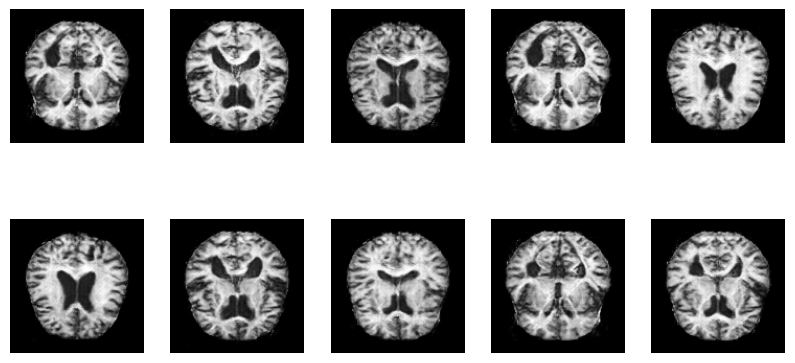

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - d_loss: -1.2396 - g_loss: 2.6013
Epoch 113/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 576ms/step - d_loss: -1.0908 - g_loss: 2.4643
Epoch 114/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.0473 - g_loss: 2.5258
Epoch 115/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.3320 - g_loss: 3.2878
Epoch 116/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.0893 - g_loss: 2.3534
Epoch 117/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.2648 - g_loss: 2.4061
Epoch 118/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.4693 - g_loss: 2.6563
Epoch 119/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 531ms/step - d_loss: -1.2656 - g_loss: 2.5903
Epoch 120/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 573ms/step - d_loss: -1.3229 - g_loss: 2.9541
Epoch 121/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.3677 - g_loss: 3.4621
Epoch 122/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -1.2256 - g_loss: 3.6298
Epoch 123/352
12/12 ━━━━

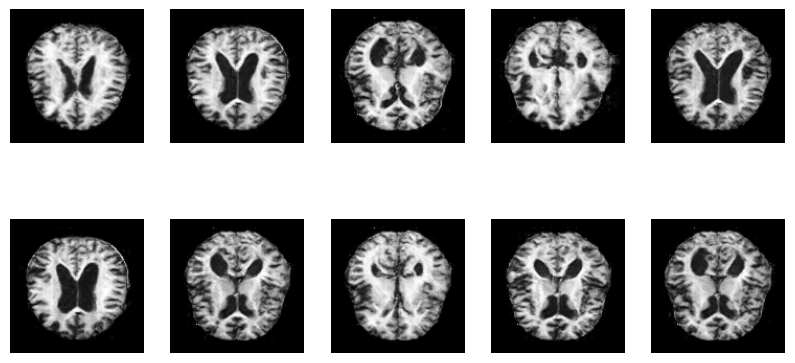

Epoch 128 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  32


Added 32 more epochs.
12/12 ━━━━━━━━━━━━━━━━━━━━ 18s 2s/step - d_loss: -1.3538 - g_loss: 4.5269  
Epoch 129/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 521ms/step - d_loss: -1.3421 - g_loss: 4.0200
Epoch 130/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 528ms/step - d_loss: -1.3405 - g_loss: 4.6736
Epoch 131/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 540ms/step - d_loss: -1.4953 - g_loss: 4.4620
Epoch 132/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 595ms/step - d_loss: -1.3950 - g_loss: 4.3160
Epoch 133/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 562ms/step - d_loss: -1.4394 - g_loss: 5.0380
Epoch 134/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 557ms/step - d_loss: -1.3041 - g_loss: 4.9951
Epoch 135/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 542ms/step - d_loss: -1.2642 - g_loss: 6.1104
Epoch 136/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -1.3990 - g_loss: 5.1065
Epoch 137/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 529ms/step - d_loss: -1.3362 - g_loss: 5.4796
Epoch 138/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 527ms/step - d_loss: -1.5276 - g_loss: 5.8864
Ep

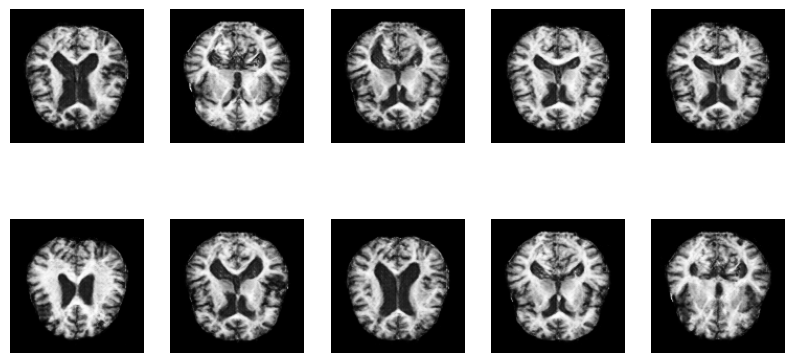

12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 569ms/step - d_loss: -1.4147 - g_loss: 6.3375
Epoch 145/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 538ms/step - d_loss: -1.4369 - g_loss: 6.7333
Epoch 146/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 536ms/step - d_loss: -1.2645 - g_loss: 7.2239
Epoch 147/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 535ms/step - d_loss: -1.4301 - g_loss: 6.5730
Epoch 148/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 534ms/step - d_loss: -1.5992 - g_loss: 6.9265
Epoch 149/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.4973 - g_loss: 6.8762
Epoch 150/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.4709 - g_loss: 6.9088
Epoch 151/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.2970 - g_loss: 7.5936
Epoch 152/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.3605 - g_loss: 7.5952
Epoch 153/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 532ms/step - d_loss: -1.5528 - g_loss: 6.9969
Epoch 154/352
12/12 ━━━━━━━━━━━━━━━━━━━━ 7s 533ms/step - d_loss: -1.5268 - g_loss: 7.5862
Epoch 155/352
12/12 ━━━━

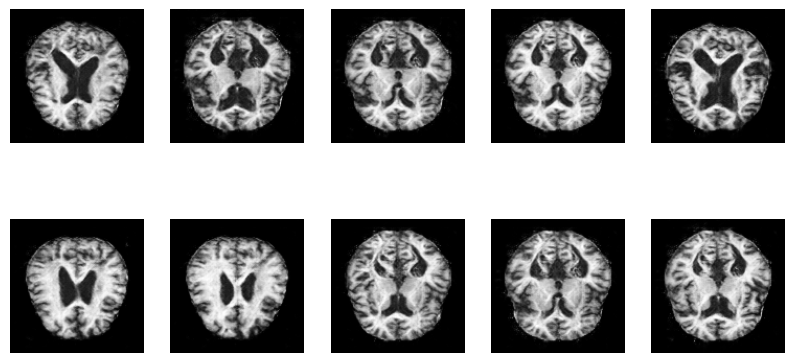

Epoch 160 completed. Do you want to stop training or add more epochs? (stop/add):  stop


Stopping training as requested by the user.
12/12 ━━━━━━━━━━━━━━━━━━━━ 47s 4s/step - d_loss: -1.5908 - g_loss: 8.7770  


In [27]:
Mild_model = train_DCGAN(Mild_train_gen,ask_epoch=32,freq = 16,batch_size = 64,EPOCHS = 352)

Found 1792 validated image filenames.


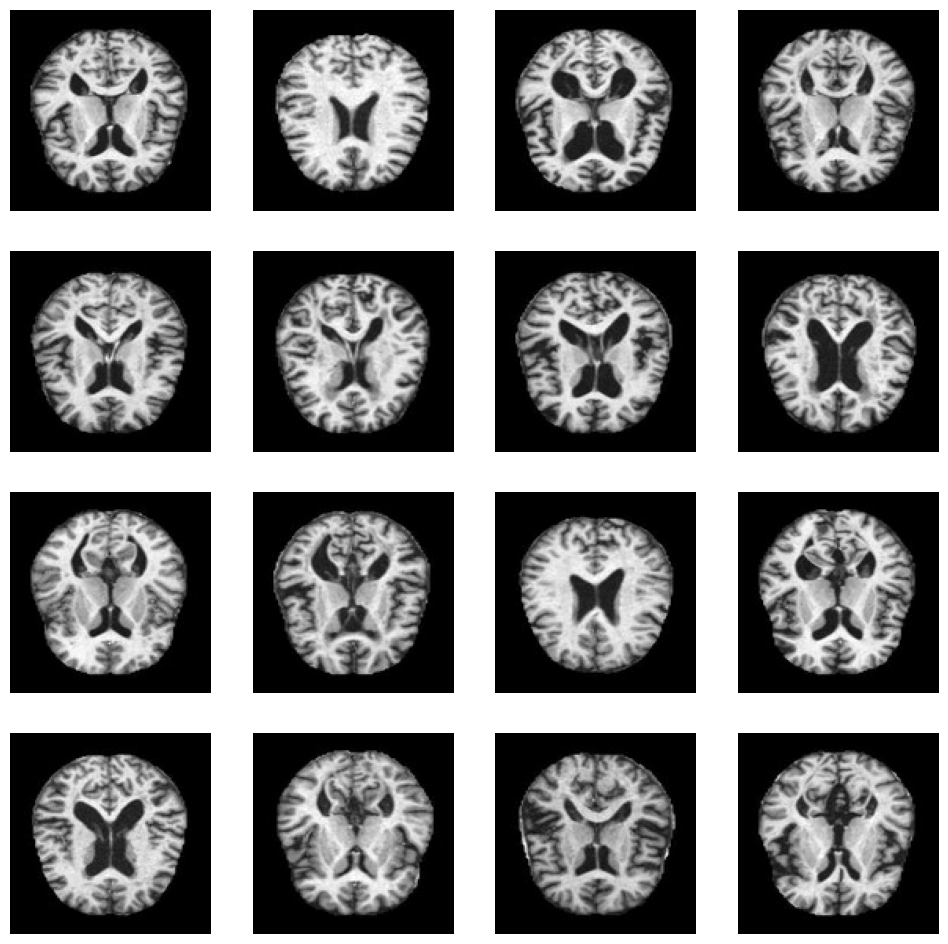

In [28]:
Very_Mild_train_gen = Image_Data_Generator(Very_Mild_generate_set,batch_size = 64)
sample_images = next(Very_Mild_train_gen)
dispaly_image_generator(sample_images)

Epoch 1/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 50s 561ms/step - d_loss: -6.2742 - g_loss: 2.4196
Epoch 2/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 584ms/step - d_loss: -15.1553 - g_loss: 5.6665
Epoch 3/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 597ms/step - d_loss: -8.5853 - g_loss: 0.3867
Epoch 4/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 572ms/step - d_loss: -6.8373 - g_loss: -0.8617
Epoch 5/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 566ms/step - d_loss: -6.0044 - g_loss: -1.7956

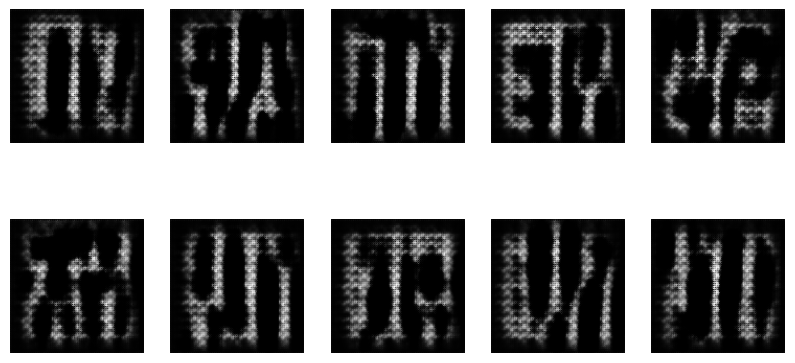

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 578ms/step - d_loss: -6.0149 - g_loss: -1.8749
Epoch 6/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 570ms/step - d_loss: -4.0559 - g_loss: -4.0950
Epoch 7/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 578ms/step - d_loss: -3.4288 - g_loss: -3.2137
Epoch 8/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -3.7024 - g_loss: -3.5585
Epoch 9/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -3.7812 - g_loss: -3.7722
Epoch 10/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -3.5944 - g_loss: -4.0945

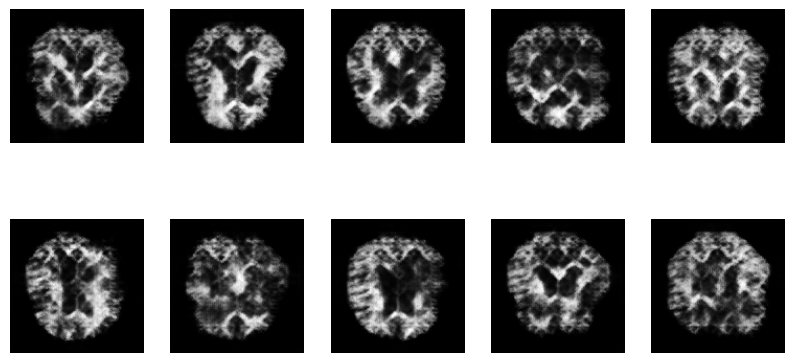

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 588ms/step - d_loss: -3.5954 - g_loss: -4.1179
Epoch 11/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -3.2211 - g_loss: -4.6425
Epoch 12/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -2.7723 - g_loss: -4.6021
Epoch 13/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -2.3827 - g_loss: -4.5873
Epoch 14/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 576ms/step - d_loss: -1.9312 - g_loss: -4.4822
Epoch 15/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 576ms/step - d_loss: -1.5465 - g_loss: -4.4425

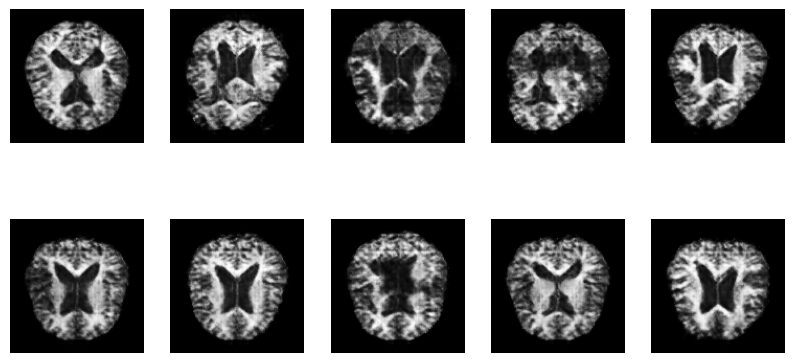

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 590ms/step - d_loss: -1.5393 - g_loss: -4.4157
Epoch 16/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -1.4000 - g_loss: -4.0280
Epoch 17/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -1.1788 - g_loss: -3.9157
Epoch 18/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.8989 - g_loss: -3.4324
Epoch 19/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 574ms/step - d_loss: -0.7680 - g_loss: -3.1729
Epoch 20/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - d_loss: -0.6868 - g_loss: -2.9529

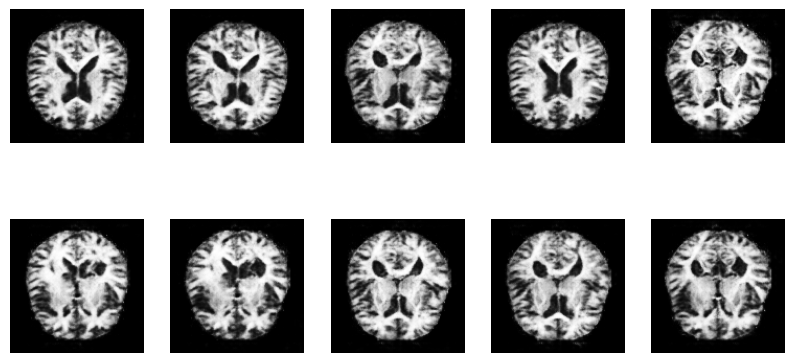

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 587ms/step - d_loss: -0.6926 - g_loss: -2.9760
Epoch 21/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 574ms/step - d_loss: -0.6962 - g_loss: -3.2677
Epoch 22/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.6464 - g_loss: -2.7871
Epoch 23/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.7580 - g_loss: -2.5367
Epoch 24/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 578ms/step - d_loss: -0.6811 - g_loss: -1.8114
Epoch 25/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 574ms/step - d_loss: -0.6680 - g_loss: -1.9455

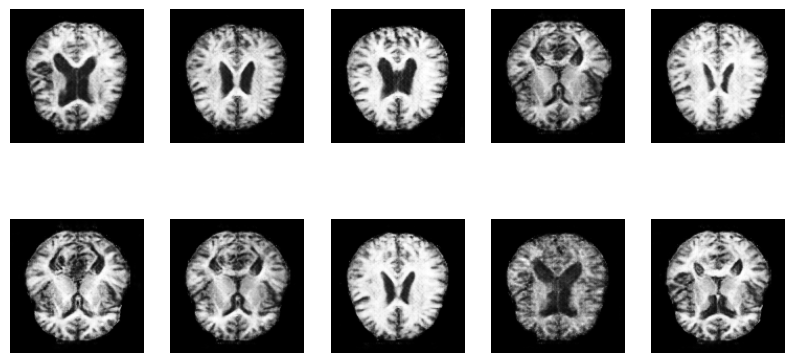

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 587ms/step - d_loss: -0.6726 - g_loss: -1.9343
Epoch 26/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.7433 - g_loss: -1.9914
Epoch 27/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.7859 - g_loss: -1.4737
Epoch 28/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.7745 - g_loss: -1.0062
Epoch 29/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 574ms/step - d_loss: -0.7842 - g_loss: -0.9027
Epoch 30/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 575ms/step - d_loss: -0.7640 - g_loss: -0.7615

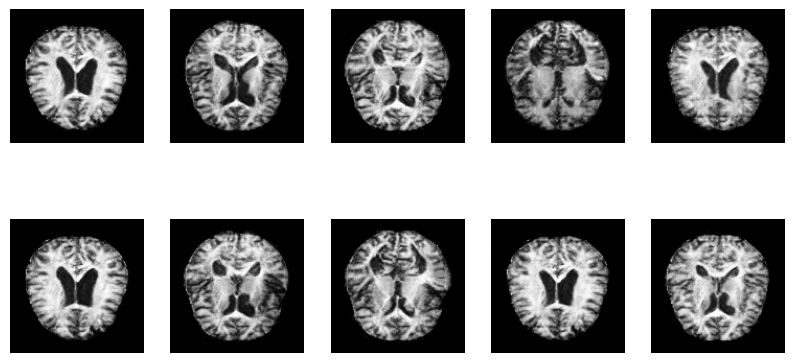

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 588ms/step - d_loss: -0.7608 - g_loss: -0.7418
Epoch 31/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 576ms/step - d_loss: -0.7992 - g_loss: -0.8673
Epoch 32/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.8247 - g_loss: -0.4609
Epoch 33/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.8062 - g_loss: 0.0977
Epoch 34/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 577ms/step - d_loss: -0.8848 - g_loss: 0.3212
Epoch 35/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -0.9236 - g_loss: 0.5769

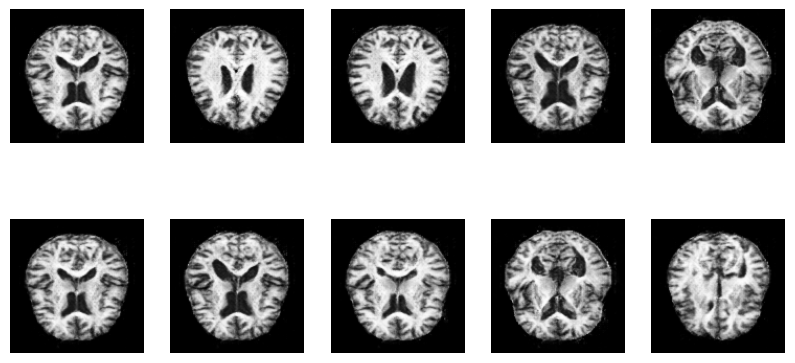

28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 591ms/step - d_loss: -0.9283 - g_loss: 0.5987
Epoch 36/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.8498 - g_loss: 0.8215
Epoch 37/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 576ms/step - d_loss: -0.9122 - g_loss: 1.3011
Epoch 38/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.8652 - g_loss: 1.5042
Epoch 39/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -0.9000 - g_loss: 1.7804
Epoch 40/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - d_loss: -0.9378 - g_loss: 2.4234

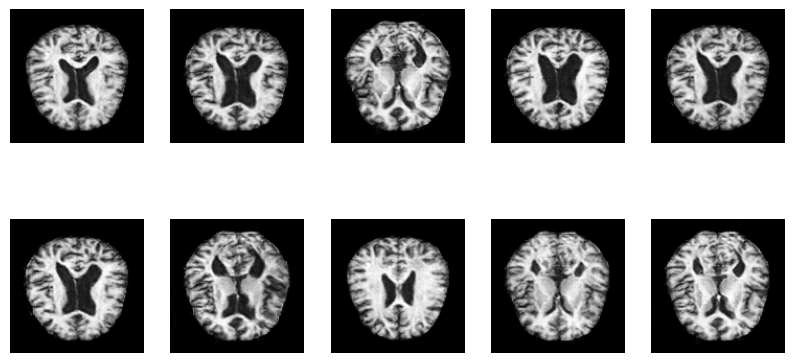

Epoch 40 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
28/28 ━━━━━━━━━━━━━━━━━━━━ 26s 926ms/step - d_loss: -0.9425 - g_loss: 2.4442
Epoch 41/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 568ms/step - d_loss: -0.8716 - g_loss: 2.7600
Epoch 42/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 595ms/step - d_loss: -0.8676 - g_loss: 2.7776
Epoch 43/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 593ms/step - d_loss: -0.9589 - g_loss: 3.4112
Epoch 44/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 571ms/step - d_loss: -0.9692 - g_loss: 3.6554
Epoch 45/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - d_loss: -0.8517 - g_loss: 3.4480

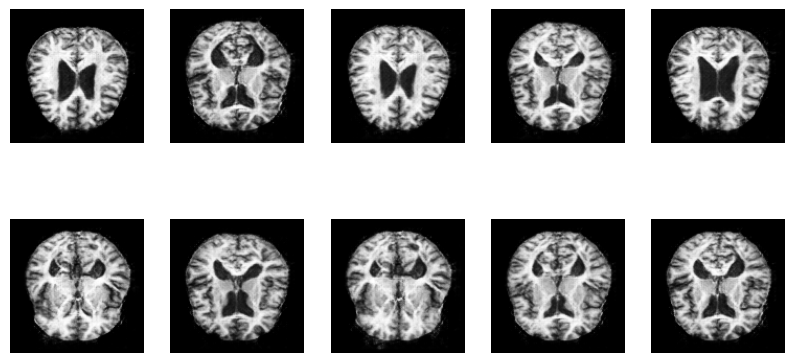

Epoch 45 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
28/28 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - d_loss: -0.8551 - g_loss: 3.4575  
Epoch 46/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 562ms/step - d_loss: -0.9844 - g_loss: 4.1257
Epoch 47/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 587ms/step - d_loss: -0.9559 - g_loss: 4.6708
Epoch 48/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 598ms/step - d_loss: -0.6767 - g_loss: 4.7735
Epoch 49/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 571ms/step - d_loss: -0.6875 - g_loss: 3.1512
Epoch 50/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - d_loss: -0.6851 - g_loss: 6.2244

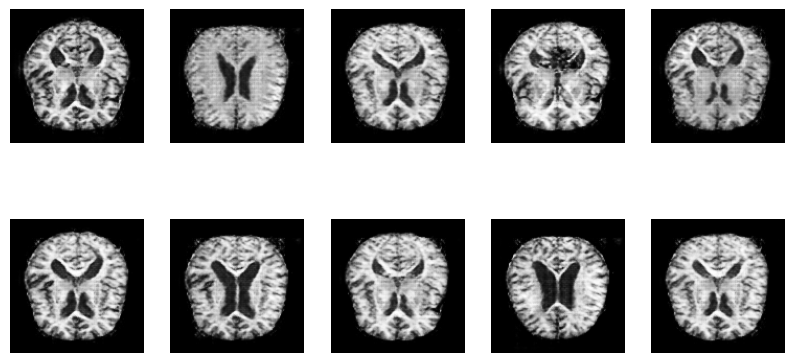

Epoch 50 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
28/28 ━━━━━━━━━━━━━━━━━━━━ 26s 940ms/step - d_loss: -0.6884 - g_loss: 6.2826
Epoch 51/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 565ms/step - d_loss: -0.9530 - g_loss: 8.6204
Epoch 52/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 593ms/step - d_loss: -0.9353 - g_loss: 8.4172
Epoch 53/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 593ms/step - d_loss: -1.1297 - g_loss: 8.7886
Epoch 54/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 573ms/step - d_loss: -1.0867 - g_loss: 8.7642
Epoch 55/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 568ms/step - d_loss: -1.1023 - g_loss: 9.1856

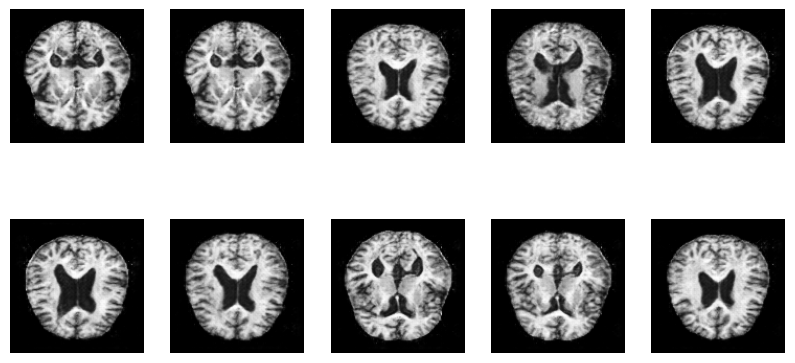

Epoch 55 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
28/28 ━━━━━━━━━━━━━━━━━━━━ 45s 2s/step - d_loss: -1.1031 - g_loss: 9.1683  
Epoch 56/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 561ms/step - d_loss: -1.1966 - g_loss: 9.5574
Epoch 57/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 585ms/step - d_loss: -1.0850 - g_loss: 9.2248
Epoch 58/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 599ms/step - d_loss: -1.0614 - g_loss: 9.4076
Epoch 59/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 574ms/step - d_loss: -1.0629 - g_loss: 9.9766
Epoch 60/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - d_loss: -1.0962 - g_loss: 10.5758

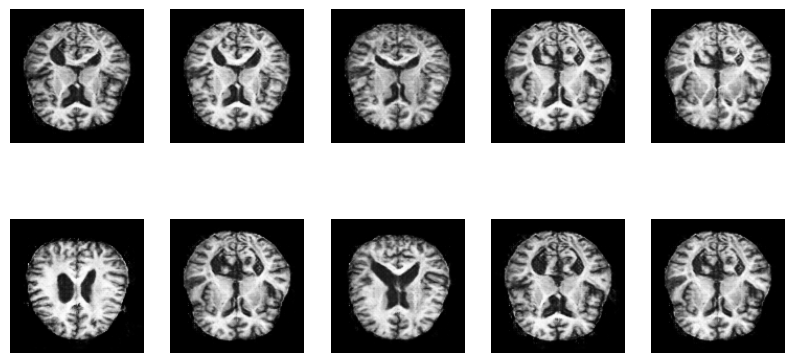

Epoch 60 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
28/28 ━━━━━━━━━━━━━━━━━━━━ 75s 3s/step - d_loss: -1.0918 - g_loss: 10.5948  
Epoch 61/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 16s 557ms/step - d_loss: -1.0097 - g_loss: 10.6201
Epoch 62/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 581ms/step - d_loss: -1.1282 - g_loss: 10.9449
Epoch 63/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 597ms/step - d_loss: -1.1992 - g_loss: 11.2121
Epoch 64/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 17s 575ms/step - d_loss: -1.0249 - g_loss: 11.4686
Epoch 65/200
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 567ms/step - d_loss: -1.0686 - g_loss: 11.1165

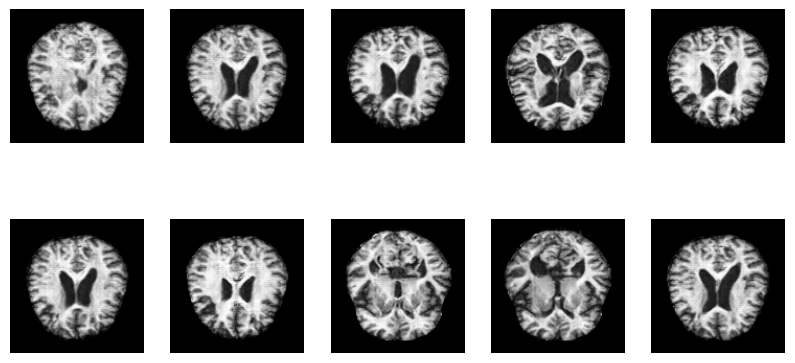

Epoch 65 completed. Do you want to stop training or add more epochs? (stop/add):  stop


Stopping training as requested by the user.
28/28 ━━━━━━━━━━━━━━━━━━━━ 65s 2s/step - d_loss: -1.0718 - g_loss: 11.1403  


In [29]:
Very_model = train_DCGAN(Very_Mild_train_gen,ask_epoch=40,batch_size = 64,EPOCHS = 200,freq = 5)

Found 2560 validated image filenames.


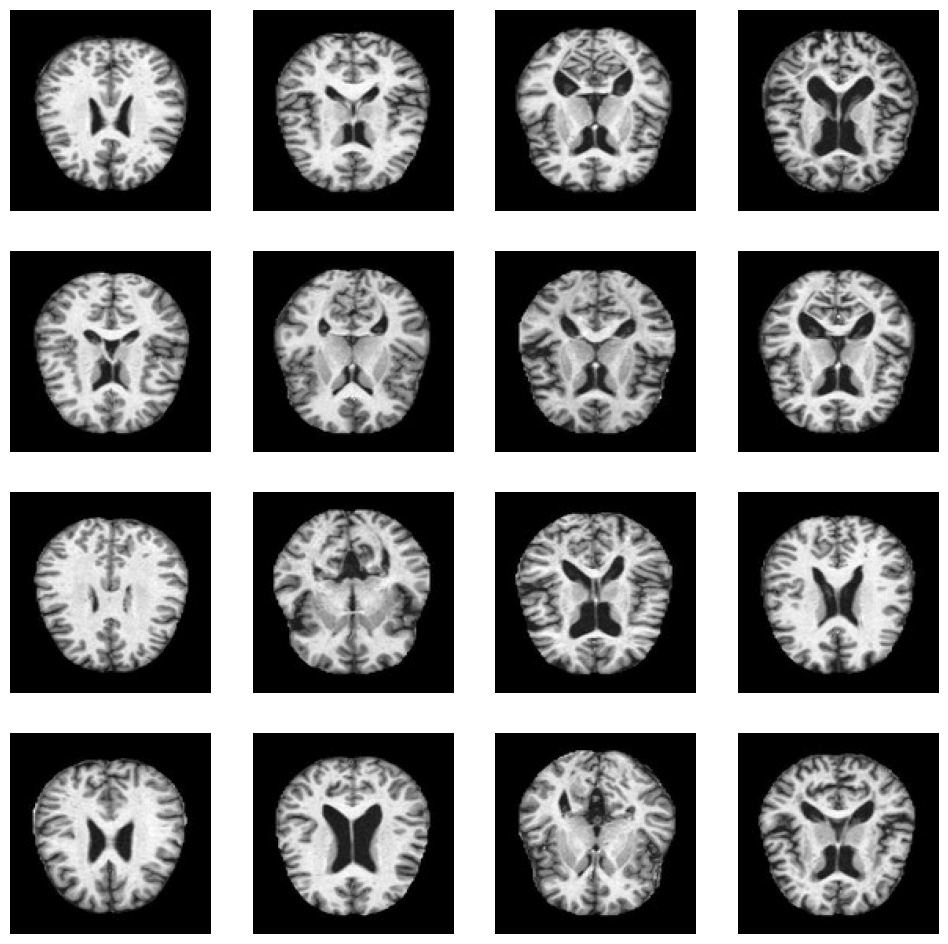

In [30]:
Non_Mild_train_gen = Image_Data_Generator(Non_generate_set,batch_size = 64)
sample_images= next(Non_Mild_train_gen)
dispaly_image_generator(sample_images)

Epoch 1/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 53s 565ms/step - d_loss: -4.7975 - g_loss: 2.3153
Epoch 2/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 596ms/step - d_loss: -8.0213 - g_loss: 1.2225
Epoch 3/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 571ms/step - d_loss: -7.0444 - g_loss: -0.7336
Epoch 4/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 568ms/step - d_loss: -7.4579 - g_loss: -1.4540
Epoch 5/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -5.4340 - g_loss: -2.4978

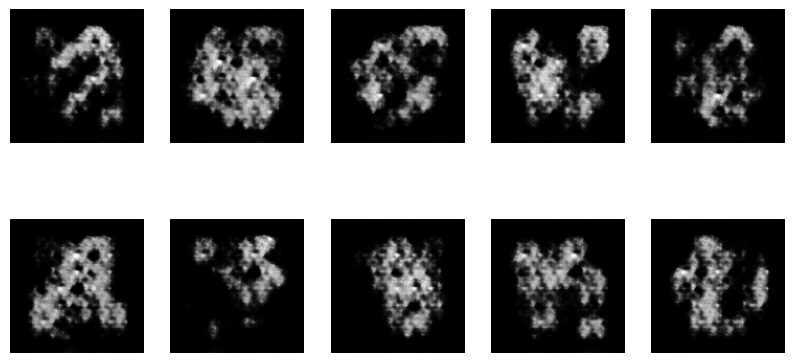

40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 585ms/step - d_loss: -5.4548 - g_loss: -2.4675
Epoch 6/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 575ms/step - d_loss: -5.8317 - g_loss: -2.1788
Epoch 7/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 574ms/step - d_loss: -6.0569 - g_loss: -2.0534
Epoch 8/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 575ms/step - d_loss: -5.7925 - g_loss: -2.3066
Epoch 9/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 575ms/step - d_loss: -4.4019 - g_loss: -2.1470
Epoch 10/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 573ms/step - d_loss: -4.0059 - g_loss: -0.5943

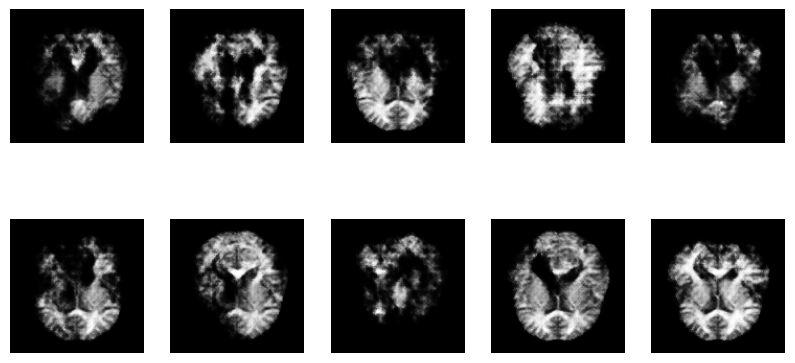

Epoch 10 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
40/40 ━━━━━━━━━━━━━━━━━━━━ 67s 2s/step - d_loss: -4.0052 - g_loss: -0.6139  
Epoch 11/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 566ms/step - d_loss: -3.6929 - g_loss: 0.2312
Epoch 12/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 598ms/step - d_loss: -2.4229 - g_loss: 0.3164
Epoch 13/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 570ms/step - d_loss: -1.5054 - g_loss: 1.5218
Epoch 14/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 568ms/step - d_loss: -1.2147 - g_loss: 2.2305
Epoch 15/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -1.2454 - g_loss: 2.8023

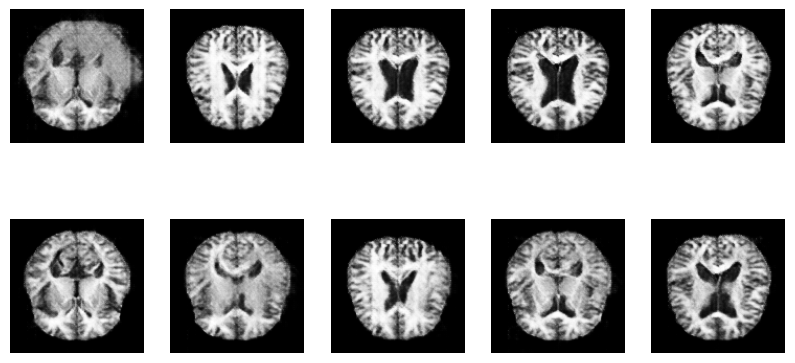

Epoch 15 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
40/40 ━━━━━━━━━━━━━━━━━━━━ 29s 719ms/step - d_loss: -1.2573 - g_loss: 2.8603
Epoch 16/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 576ms/step - d_loss: -1.3478 - g_loss: 3.5916
Epoch 17/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 580ms/step - d_loss: -1.3930 - g_loss: 3.6724
Epoch 18/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 571ms/step - d_loss: -1.3716 - g_loss: 5.0899
Epoch 19/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 574ms/step - d_loss: -1.3017 - g_loss: 5.1678
Epoch 20/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -1.4367 - g_loss: 5.5021

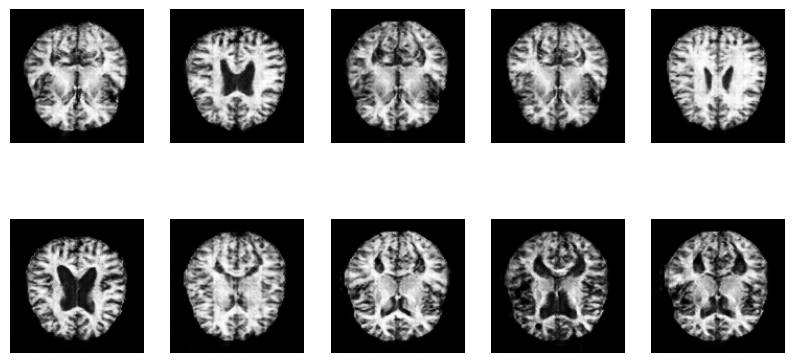

Epoch 20 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
40/40 ━━━━━━━━━━━━━━━━━━━━ 30s 735ms/step - d_loss: -1.4171 - g_loss: 5.4740
Epoch 21/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 577ms/step - d_loss: -1.2480 - g_loss: 6.1143
Epoch 22/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 580ms/step - d_loss: -1.3172 - g_loss: 5.9595
Epoch 23/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 568ms/step - d_loss: -1.2541 - g_loss: 6.1081
Epoch 24/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 574ms/step - d_loss: -1.3731 - g_loss: 6.6623
Epoch 25/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -1.3554 - g_loss: 7.2826

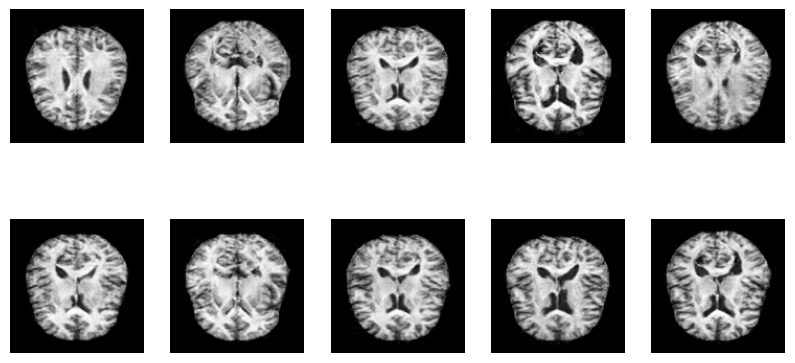

Epoch 25 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
40/40 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - d_loss: -1.3567 - g_loss: 7.2932  
Epoch 26/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 567ms/step - d_loss: -1.4207 - g_loss: 7.2713
Epoch 27/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 598ms/step - d_loss: -1.4125 - g_loss: 7.7021
Epoch 28/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 570ms/step - d_loss: -1.4132 - g_loss: 8.0995
Epoch 29/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 568ms/step - d_loss: -1.5108 - g_loss: 8.3375
Epoch 30/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -1.5567 - g_loss: 8.5933

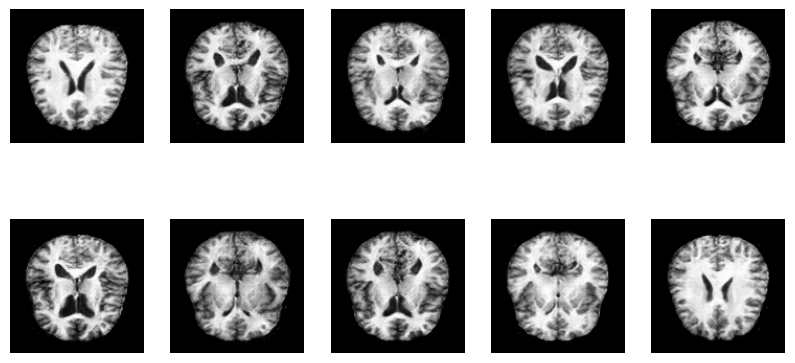

Epoch 30 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
40/40 ━━━━━━━━━━━━━━━━━━━━ 31s 765ms/step - d_loss: -1.5612 - g_loss: 8.6114
Epoch 31/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 572ms/step - d_loss: -1.5470 - g_loss: 8.9980
Epoch 32/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 24s 586ms/step - d_loss: -1.5105 - g_loss: 9.5677
Epoch 33/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 571ms/step - d_loss: -1.4872 - g_loss: 9.9699
Epoch 34/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 23s 572ms/step - d_loss: -1.5716 - g_loss: 10.3085
Epoch 35/150
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 577ms/step - d_loss: -1.5404 - g_loss: 11.0473

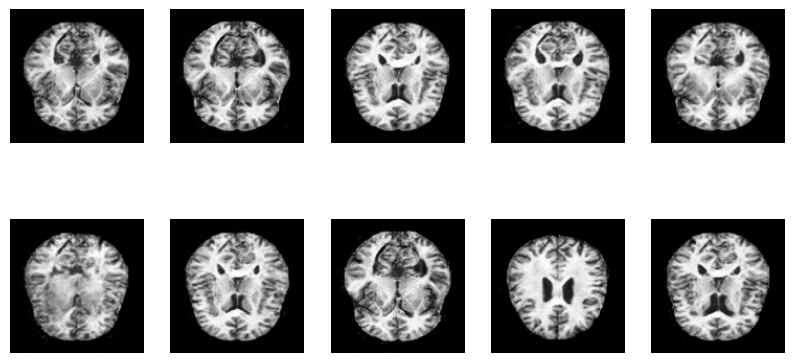

Epoch 35 completed. Do you want to stop training or add more epochs? (stop/add):  stop


Stopping training as requested by the user.
40/40 ━━━━━━━━━━━━━━━━━━━━ 113s 3s/step - d_loss: -1.5389 - g_loss: 11.0490 


In [42]:
Non_model = train_DCGAN(Non_Mild_train_gen,ask_epoch = 10,batch_size = 64,EPOCHS = 150,freq = 5)

In [48]:

# Moderate_model.generator.save("Moderate_generator.h5")
generate_and_save_images(load_model('/kaggle/input/moderate/keras/default/1/Moderate_generator (1).h5'),num_images=19949,subfolder_name='Moderate_Demented',batch_size = 256)

19949 images saved in 'Dataset/Moderate_Demented' directory.


In [49]:
# Mild_model.generator.save("Mild_generator.h5")
generate_and_save_images(load_model('/kaggle/input/mild/keras/default/1/Mild_generator (1).h5'),num_images=19284,subfolder_name='Mild_Demented',batch_size = 256)

19284 images saved in 'Dataset/Mild_Demented' directory.


In [50]:
# Very_model.generator.save("Very_generator.h5")
generate_and_save_images(load_model('/kaggle/input/very/keras/default/1/Very_generator (1).h5'),num_images=18208,subfolder_name='Very_Mild_Demented',batch_size = 256)

18208 images saved in 'Dataset/Very_Mild_Demented' directory.


In [51]:
# Non_model.generator.save("Non_generator.h5")
generate_and_save_images(load_model('/kaggle/input/non/keras/default/1/Non_generator (1).h5'),num_images=17440,subfolder_name='Non_Demented',batch_size = 256)

17440 images saved in 'Dataset/Non_Demented' directory.


In [52]:
Moderate_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Moderate_Demented','Moderate_Demented')
Mild_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Mild_Demented','Mild_Demented')
Very_Mild_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Very_Mild_Demented','Very_Mild_Demented')
Non_Demented_Original = read(r'/kaggle/input/alzheimer/Dataset/Non_Demented','Non_Demented')
Original_Dataset = pd.concat([Moderate_Demented_Original, Mild_Demented_Original, Very_Mild_Demented_Original, Non_Demented_Original])

Original_Dataset.head(5)

,filepaths,label
0,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
1,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
2,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
3,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented
4,/kaggle/input/alzheimer/Dataset/Moderate_Demen...,Moderate_Demented


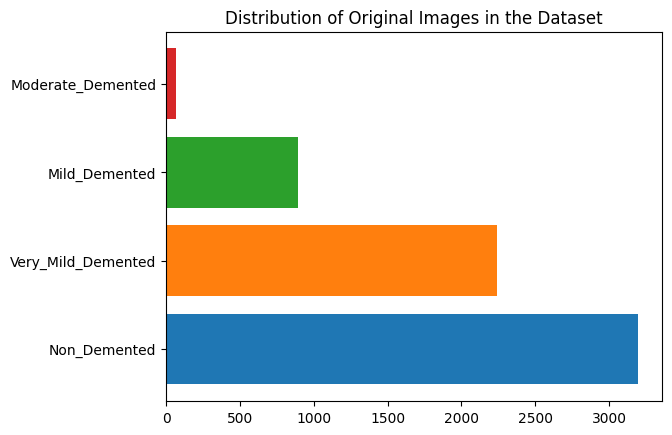

In [53]:
plt.barh(width = Original_Dataset['label'].value_counts(), y = Original_Dataset['label'].value_counts().index,color=plt.cm.tab10.colors,)
plt.title('Distribution of Original Images in the Dataset')
plt.show()

In [54]:
Moderate_Demented = read(r'/kaggle/working/Dataset/Moderate_Demented','Moderate_Demented')
Mild_Demented = read(r'/kaggle/working/Dataset/Mild_Demented','Mild_Demented')
Very_Mild_Demented = read(r'/kaggle/working/Dataset/Very_Mild_Demented','Very_Mild_Demented')
Non_Demented = read(r'/kaggle/working/Dataset/Non_Demented','Non_Demented')
combined_df = pd.concat([Moderate_Demented, Mild_Demented, Very_Mild_Demented, Non_Demented,Moderate_generate_set,Mild_generate_set,Very_Mild_generate_set,Non_generate_set])
shuffled_df = shuffle(combined_df, random_state=44)

shuffled_df.head(5)

,filepaths,label
17435,/kaggle/working/Dataset/Very_Mild_Demented/Ver...,Very_Mild_Demented
8996,/kaggle/working/Dataset/Very_Mild_Demented/Ver...,Very_Mild_Demented
949,/kaggle/working/Dataset/Very_Mild_Demented/Ver...,Very_Mild_Demented
6893,/kaggle/working/Dataset/Very_Mild_Demented/Ver...,Very_Mild_Demented
2954,/kaggle/working/Dataset/Non_Demented/Non_Demen...,Non_Demented


In [55]:
val_set = pd.concat([Moderate_val_set, Mild_val_set, Very_Mild_val_set, Non_val_set])
val_set = shuffle(val_set, random_state=44)

val_set.head(5)

,filepaths,label
416,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented
1369,/kaggle/input/alzheimer/Dataset/Very_Mild_Deme...,Very_Mild_Demented
524,/kaggle/input/alzheimer/Dataset/Very_Mild_Deme...,Very_Mild_Demented
803,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented
200,/kaggle/input/alzheimer/Dataset/Mild_Demented/...,Mild_Demented


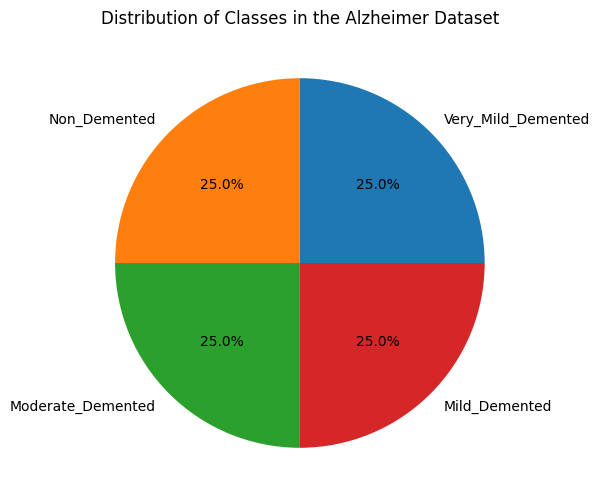

In [56]:
plt.figure(figsize= (10,6))
plt.pie(x = shuffled_df['label'].value_counts(), labels = shuffled_df['label'].value_counts().index,colors=plt.cm.tab10.colors,autopct='%1.1f%%')
plt.title('Distribution of Classes in the Alzheimer Dataset')
plt.show()

In [57]:
shuffled_df['label'].value_counts()

label
Very_Mild_Demented    20000
Non_Demented          20000
Moderate_Demented     20000
Mild_Demented         20000
Name: count, dtype: int64

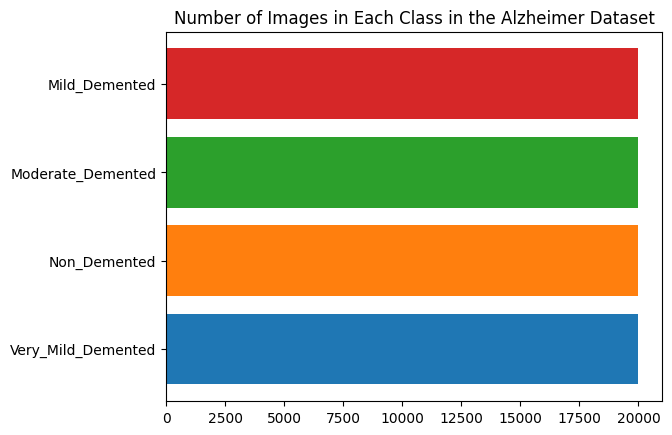

In [58]:
plt.barh(width = shuffled_df['label'].value_counts(), y = shuffled_df['label'].value_counts().index,color=plt.cm.tab10.colors,)
plt.title('Number of Images in Each Class in the Alzheimer Dataset')
plt.show()

In [77]:
df_train,df_val = Image_Data_Generator_for_cnn(shuffled_df,val_set,batch_size=32)

Found 80000 validated image filenames belonging to 4 classes.
Found 1281 validated image filenames belonging to 4 classes.


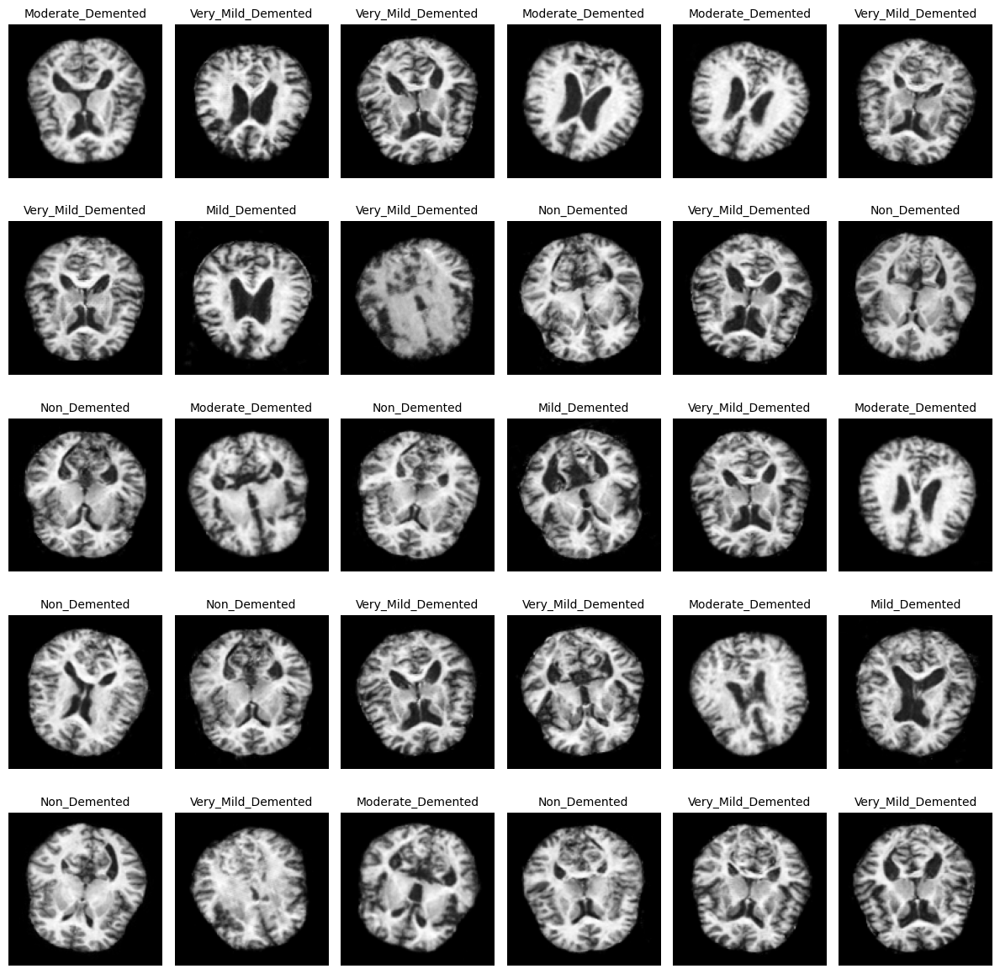

In [78]:
sample_images, image_labels = next(df_train)  # Assuming df_train is a DataGenerator
class_names = df_train.class_indices  # Mapping of class indices to names
class_names = {v: k for k, v in class_names.items()}  # Reverse mapping to get index->class

plt.figure(figsize=(12, 12))
for i in range(30):
    ax = plt.subplot(5, 6, i + 1)
    plt.imshow(sample_images[i], cmap='gray')  # Assuming grayscale images
    plt.axis("off")
    plt.title(class_names[image_labels[i].argmax()], fontsize=10)  # Get class name using argmax
plt.tight_layout()
plt.show()


In [ ]:
model = Sequential()

# Block 1
model.add(Conv2D(32, (5, 5), activation='relu', input_shape=(128, 128, 1), padding='same', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(SpatialDropout2D(0.2))

# Block 2
model.add(Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(SpatialDropout2D(0.3))

# Block 3
model.add(Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(SpatialDropout2D(0.3))

# Block 4
model.add(Conv2D(256, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.001)))
model.add(BatchNormalization())
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(SpatialDropout2D(0.4))

# Fully Connected Layers
model.add(GlobalAveragePooling2D())
model.add(Dense(256, activation='relu', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.4))
model.add(Dense(512, activation='relu', kernel_regularizer=l2(0.001)))
model.add(Dropout(0.5))
model.add(Dense(4, activation='softmax'))

# Compile Model
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

model.summary()

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./model.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-7, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=5)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("model.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)
plot_model(model, to_file='EfficientNetB0.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)    

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_64 (Conv2D)              │ (None, 128, 128, 32)   │           832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_62          │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_52 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d               │ (None, 64, 64, 32)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_65 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_63          │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_53 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_1             │ (None, 32, 32, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_66 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_64          │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_54 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_2             │ (None, 16, 16, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_67 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_65          │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_55 (MaxPooling2D) │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout2d_3             │ (None, 8, 8, 256)      │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 589,700 (2.25 MB)

 Trainable params: 588,740 (2.25 MB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/50
   4/2500 ━━━━━━━━━━━━━━━━━━━━ 1:46 43ms/step - accuracy: 0.2311 - loss: 2.6283 

I0000 00:00:1734577193.475080      93 asm_compiler.cc:369] ptxas warning : Registers are spilled to local memory in function 'loop_add_subtract_fusion', 4 bytes spill stores, 12 bytes spill loads



2500/2500 ━━━━━━━━━━━━━━━━━━━━ 152s 56ms/step - accuracy: 0.6377 - loss: 1.4300 - val_accuracy: 0.2217 - val_loss: 2.9312 - learning_rate: 0.0010
Epoch 2/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 137s 55ms/step - accuracy: 0.9199 - loss: 0.4611 - val_accuracy: 0.3872 - val_loss: 1.9408 - learning_rate: 0.0010
Epoch 3/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 138s 55ms/step - accuracy: 0.9358 - loss: 0.3854 - val_accuracy: 0.4910 - val_loss: 1.3703 - learning_rate: 0.0010
Epoch 4/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 137s 55ms/step - accuracy: 0.9430 - loss: 0.3549 - val_accuracy: 0.5121 - val_loss: 1.2687 - learning_rate: 0.0010
Epoch 5/50
2497/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9474 - loss: 0.3365

Model: "functional_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 64, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 32, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_2              │ (None, 16, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_33          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_3              │ (None, 8, 8, 256)      │        34,176 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_34          │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_18 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 80,877 (315.93 KB)

 Trainable params: 79,917 (312.18 KB)

 Non-trainable params: 960 (3.75 KB)

Epoch 1/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 144s 55ms/step - accuracy: 0.6484 - loss: 0.8881 - val_accuracy: 0.5137 - val_loss: 1.5967 - learning_rate: 1.0000e-04
Epoch 2/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 135s 54ms/step - accuracy: 0.9483 - loss: 0.1926 - val_accuracy: 0.5113 - val_loss: 1.4179 - learning_rate: 1.0000e-04
Epoch 3/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 135s 54ms/step - accuracy: 0.9604 - loss: 0.1461 - val_accuracy: 0.4809 - val_loss: 1.6190 - learning_rate: 1.0000e-04
Epoch 4/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 137s 54ms/step - accuracy: 0.9636 - loss: 0.1288 - val_accuracy: 0.4614 - val_loss: 1.7060 - learning_rate: 1.0000e-04
Epoch 5/50
2493/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.9671 - loss: 0.1185

Epoch 5 completed. Do you want to stop training or add more epochs? (stop/add):  add
How many more epochs to add?  5


Added 5 more epochs.
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 239s 95ms/step - accuracy: 0.9671 - loss: 0.1185 - val_accuracy: 0.5433 - val_loss: 1.3817 - learning_rate: 1.0000e-04
Epoch 6/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 135s 54ms/step - accuracy: 0.9678 - loss: 0.1073 - val_accuracy: 0.5222 - val_loss: 1.2557 - learning_rate: 1.0000e-04
Epoch 7/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 137s 55ms/step - accuracy: 0.9684 - loss: 0.1037 - val_accuracy: 0.3037 - val_loss: 2.5388 - learning_rate: 1.0000e-04
Epoch 8/50
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 133s 53ms/step - accuracy: 0.9694 - loss: 0.0978 - val_accuracy: 0.4044 - val_loss: 2.0002 - learning_rate: 1.0000e-04
Epoch 9/50
2493/2500 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9694 - loss: 0.0965
Epoch 9: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 134s 53ms/step - accuracy: 0.9694 - loss: 0.0965 - val_accuracy: 0.4723 - val_loss: 1.3957 - learning_rate: 1.0000e-04
Epoch 10/50
2493/2500 ━━━━━━━━

Epoch 10 completed. Do you want to stop training or add more epochs? (stop/add):  stop


Stopping training as requested by the user.
2500/2500 ━━━━━━━━━━━━━━━━━━━━ 342s 137ms/step - accuracy: 0.9723 - loss: 0.0872 - val_accuracy: 0.5379 - val_loss: 1.1225 - learning_rate: 2.0000e-05
Restoring model weights from the end of the best epoch: 10.
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.5554 - loss: 1.1059
Test Accuracy: 53.79%
41/41 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step


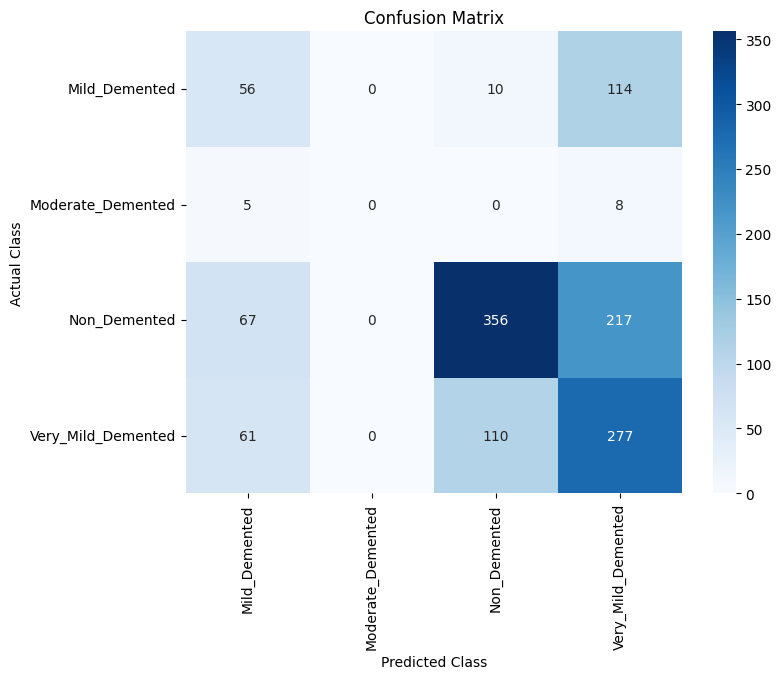

Classification Report:
                     precision    recall  f1-score   support

     Mild_Demented       0.30      0.31      0.30       180
 Moderate_Demented       0.00      0.00      0.00        13
      Non_Demented       0.75      0.56      0.64       640
Very_Mild_Demented       0.45      0.62      0.52       448

          accuracy                           0.54      1281
         macro avg       0.37      0.37      0.37      1281
      weighted avg       0.57      0.54      0.54      1281



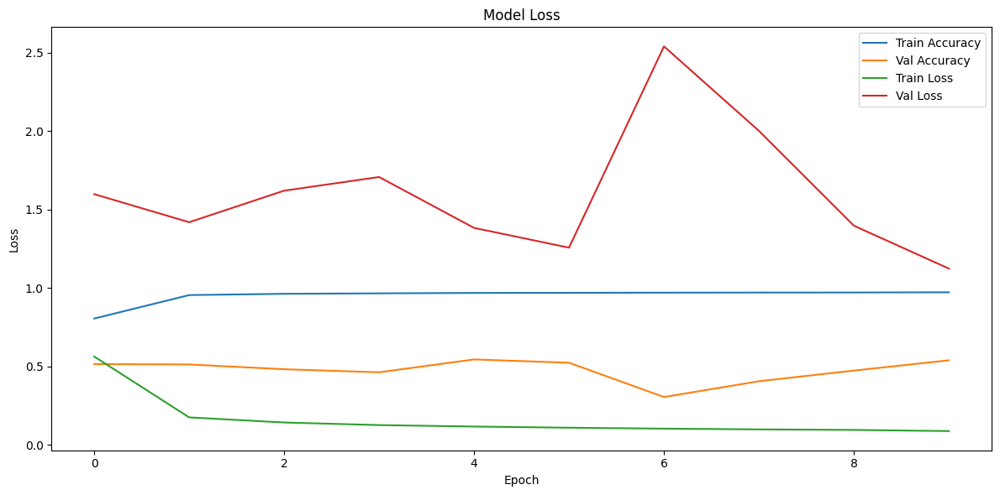

In [72]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, BatchNormalization, Activation,
    Dense, Flatten, Dropout, GlobalAveragePooling2D, Add
)
from tensorflow.keras.regularizers import l2
epochs = 50
# Create model
channelDim = 1  # Change to 1 if using channels_first format
def lightweight_cnn(input_shape=(128, 128, 3), num_classes=10):
    """A lightweight CNN model with fewer parameters."""
    inputs = Input(shape=input_shape)
    
    # Initial Block
    x = SeparableConv2D(32, (3, 3), strides=2, padding='same')(inputs)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Stage 1
    x = SeparableConv2D(64, (3, 3), strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Stage 2
    x = SeparableConv2D(128, (3, 3), strides=2, padding='same')(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Stage 3
    x = SeparableConv2D(256, (3, 3), strides=2, padding='same', )(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    
    # Global Average Pooling and Classification
    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(0.0001))(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)
    
    model = Model(inputs, outputs)
    return model


# Example usage
model = lightweight_cnn(input_shape=(128, 128, 1), num_classes=4)
model.summary()

# Compile the model
optimizer = Adam(learning_rate=0.0001)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./best_EfficientNetB0_model.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=5)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("dcgan+EfficientNetB0.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)
plot_model(model, to_file='EfficientNetB0.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)    

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, Dense, Dropout, Flatten, GlobalAveragePooling2D, BatchNormalization
)
from tensorflow.keras.applications import Xception
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Model parameters
IMAGE_SIZE = (128, 128, 3)  # Grayscale images
NUM_CLASSES = 4
epochs = 50  

# Define input layer
inputs = Input(shape=IMAGE_SIZE)

# Base EfficientNetLiteB0 model
base_model = EfficientNetB0(include_top=False, weights='imagenet', input_tensor=inputs, pooling='max')

# # Fine-tune the last 20 layers
# for layer in base_model.layers[-20:]:
#     layer.trainable = True

inputs = Input(shape=IMAGE_SIZE)
x = base_model(inputs)
x = BatchNormalization()(x)  # Normalize outputs
x = Dense(512, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.4)(x)  # Reduced dropout rate
x = Dense(256, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.4)(x)  # Reduced dropout rate
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

# Assemble the model
model = Model(inputs, outputs)

# Model summary
model.summary()

# Compile the model
optimizer = Adam(learning_rate=0.0001)
model.compile(optimizer=optimizer, loss='categorical_crossentropy', metrics=['accuracy'])

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./best_EfficientNetB0_model.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=50)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("dcgan+EfficientNetB0.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)
plot_model(model, to_file='EfficientNetB0.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)    

In [ ]:
model.save("dcgan+EfficientNetB0.h5")

In [ ]:
load_model = load_model(r'/kaggle/working/best_EfficientNetB0_model.keras') 
# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(load_model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)

In [ ]:
IMAGE_SIZE = (128, 128, 3)  # Grayscale images
NUM_CLASSES = 4
epochs = 50  

base_model = MobileNetV2(include_top=False, weights='imagenet', input_shape=IMAGE_SIZE, pooling='max',alpha=1)

# for layer in base_model.layers[:-20]:
#     layer.trainable = False

inputs = Input(shape=IMAGE_SIZE)
x = base_model(inputs)
x = BatchNormalization()(x)  # Normalize outputs
x = Dense(512, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.4)(x)  # Reduced dropout rate
x = Dense(256, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.4)(x)  # Reduced dropout rate
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)
# Compile the model
model.compile(optimizer = Adam(learning_rate=0.0001),loss='categorical_crossentropy',
              metrics=['accuracy'])

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./best_MobileNetV2_model.h5', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=50)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("dcgan+mobilenetv2.h5")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)

plot_model(model, to_file='MobileNetV2.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)      

In [ ]:
IMAGE_SIZE = (128, 128, 3)  # Grayscale images
NUM_CLASSES = 4
epochs = 50  

base_model = keras.applications.DenseNet121(include_top=False, weights='imagenet', input_shape=IMAGE_SIZE, pooling='max')

# for layer in base_model.layers[:-20]:
#     layer.trainable = False

# Define the custom classification head
inputs = Input(shape=IMAGE_SIZE)
x = base_model(inputs)
x = BatchNormalization()(x) 
x = Dense(256, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.5)(x)  
x = Dense(128, kernel_regularizer=l2(0.002))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.5)(x)  
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)
# Compile the model
model.compile(optimizer = Adam(learning_rate=0.0001),loss='categorical_crossentropy',
              metrics=['accuracy'])

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./best_DenseNet121_model.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=50)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("dcgan+DenseNet121.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)

plot_model(model, to_file='DenseNet121.png', show_shapes=True, show_layer_names=True)
plot_metrics(history)      

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, Dense, Dropout, Flatten, GlobalAveragePooling2D, BatchNormalization
)
from tensorflow.keras.applications import NASNetMobile
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Model parameters
IMAGE_SIZE = (128, 128, 3)  # Grayscale images
NUM_CLASSES = 4

# Base Xception model
base_model = NASNetMobile(include_top=False, weights='imagenet', input_shape=IMAGE_SIZE, pooling='max')
inputs = Input(shape=IMAGE_SIZE)
x = base_model(inputs)
x = BatchNormalization()(x) 
x = Dense(256, kernel_regularizer=l2(0.001))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.5)(x)  
x = Dense(128, kernel_regularizer=l2(0.001))(x)
x = LeakyReLU(alpha=0.2)(x)
x = Dropout(0.5)(x)  
outputs = Dense(NUM_CLASSES, activation="softmax")(x)

model = Model(inputs, outputs)
# Compile the model
model.compile(optimizer = Adam(learning_rate=0.0001),loss='categorical_crossentropy',
              metrics=['accuracy'])

# Callbacks
earlystopping = EarlyStopping(restore_best_weights=True, patience=10, verbose=1)
checkpoint = ModelCheckpoint('./best_model.keras', save_best_only=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=1e-6, verbose=1)

class UserPromptCallback(tf.keras.callbacks.Callback):
    def __init__(self, prompt_frequency, max_epochs=epochs):
        super(UserPromptCallback, self).__init__()
        self.prompt_frequency = prompt_frequency
        self.max_epochs = max_epochs
        self.remaining_epochs = prompt_frequency

    def on_epoch_end(self, epoch, logs=None):
        # Automatically stop if max_epochs is reached
        if epoch + 1 >= self.max_epochs:
            print(f"Reached maximum epoch {self.max_epochs}. Stopping training.")
            self.model.stop_training = True
            return
        
        # User prompt logic
        self.remaining_epochs -= 1
        if self.remaining_epochs <= 0:
            response = input(f"Epoch {epoch + 1} completed. Do you want to stop training or add more epochs? (stop/add): ").strip().lower()
            if response == 'stop':
                print("Stopping training as requested by the user.")
                self.model.stop_training = True
            elif response == 'add':
                additional_epochs = int(input("How many more epochs to add? ").strip())
                print(f"Added {additional_epochs} more epochs.")
                self.remaining_epochs = additional_epochs
user_prompt_callback = UserPromptCallback(prompt_frequency=50)

# Train the model
history = model.fit(
    df_train,  # Grayscale preprocessing
    validation_data=df_val,
    batch_size=32,
    epochs=epochs,
    callbacks=[earlystopping, checkpoint, reduce_lr,user_prompt_callback]
)
# Save the model in the TensorFlow SavedModel format
model.save("dcgan+nasa.keras")
# Load the best saved model after training
# model.load_weights("model.keras")

# Reset test generator before evaluation
df_val.reset()

# Evaluate on test data
test_loss, test_acc = model.evaluate(df_val)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

# Predictions for confusion matrix and classification report
y_true = df_val.classes  # True labels from the test generator
y_pred = np.argmax(model.predict(df_val), axis=1)  # Predicted class indices

# Confusion Matrix
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", 
            xticklabels=df_val.class_indices.keys(), 
            yticklabels=df_val.class_indices.keys())
plt.title('Confusion Matrix')
plt.ylabel('Actual Class')
plt.xlabel('Predicted Class')
plt.show()

# Classification Report
class_report = classification_report(y_true, y_pred, target_names=list(df_val.class_indices.keys()))
print("Classification Report:\n", class_report)

plot_metrics(history)    

In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import os

# Configuration
BATCH_SIZE = 32
IMAGE_SIZE = (128, 128)

# Data generator
generate_image_gen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1.0 / 255.0,
    validation_split=0.2
)

# Train generator
train_gen = generate_image_gen.flow_from_directory(
    '/kaggle/input/alzheimer/Dataset',
    target_size=IMAGE_SIZE,
    color_mode='rgb',
    class_mode=None,
    batch_size=BATCH_SIZE,
    shuffle=True,
    subset='training',
    seed=42
)

# Validation generator
val_gen = generate_image_gen.flow_from_directory(
    '/kaggle/input/alzheimer/Dataset',
    target_size=IMAGE_SIZE,
    color_mode='rgb',
    class_mode=None,
    batch_size=BATCH_SIZE,
    shuffle=False,
    subset='validation',
    seed=42
)

# Function to prepare dataset arrays for training
def prepare_dataset(generator):
    images = []
    for batch in generator:
        images.append(batch)
        if len(images) * BATCH_SIZE >= generator.samples:
            break
    return np.concatenate(images)

# Load data
train_images = prepare_dataset(train_gen)
val_images = prepare_dataset(val_gen)

# Define the autoencoder architecture
def build_autoencoder(input_shape=(128, 128, 3)):
    input_img = tf.keras.Input(shape=input_shape)

    # Encoder
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    encoded = layers.MaxPooling2D((2, 2), padding='same')(x)

    # Decoder
    x = layers.Conv2D(128, (3, 3), activation='relu', padding='same')(encoded)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    decoded = layers.Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)

    # Autoencoder
    autoencoder = models.Model(input_img, decoded)
    return autoencoder

# Build the model
autoencoder = build_autoencoder()
autoencoder.compile(optimizer='adam', loss=tf.keras.losses.MeanSquaredError())
autoencoder.summary()

# Train the autoencoder
history = autoencoder.fit(
    train_images, train_images,
    epochs=50,
    batch_size=BATCH_SIZE,
    validation_data=(val_images, val_images)
)

# Evaluate reconstruction error
reconstructed = autoencoder.predict(val_images)
reconstruction_error = np.mean((val_images - reconstructed) ** 2, axis=(1, 2, 3))

# Set an anomaly threshold
threshold = np.percentile(reconstruction_error, 95)
print("Reconstruction error threshold:", threshold)

# Identify anomalies
anomalies = reconstruction_error > threshold

# Visualize original vs reconstructed images for a few samples
def visualize_results(original, reconstructed, errors, threshold, num_samples=5):
    for i in range(num_samples):
        plt.figure(figsize=(10, 4))

        # Original image
        plt.subplot(1, 3, 1)
        plt.title("Original Image")
        plt.imshow(original[i])

        # Reconstructed image
        plt.subplot(1, 3, 2)
        plt.title("Reconstructed Image")
        plt.imshow(reconstructed[i])

        # Reconstruction error
        plt.subplot(1, 3, 3)
        plt.title(f"Reconstruction Error\n{'Anomalous' if errors[i] > threshold else 'Normal'}")
        plt.imshow((original[i] - reconstructed[i]) ** 2)

        plt.show()

# Visualize results
visualize_results(val_images, reconstructed, reconstruction_error, threshold)


In [ ]:
autoencoder.save("autoencoder_model.h5")

In [ ]:
import numpy as np
import os, cv2
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Input, MaxPooling2D, UpSampling2D, BatchNormalization
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
import glob as gb
# Load and preprocess dataset
# Assuming image data is normalized to [0, 1] and images are resized to (128, 128, 3)
# Replace the dataset path with the actual path
images = []
labels = []

class_names = ['Non_Demented', 'Very_Mild_Demented', 'Mild_Demented', 'Moderate_Demented']
class_names_label = {class_name: i for i, class_name in enumerate(class_names)}

dataset_path = r'/kaggle/input/alzheimer/Dataset'
for folder in os.listdir(dataset_path):
    path = os.path.join(dataset_path, folder, '*.jpg')
    files = gb.glob(path)
    for file in files:
        image = cv2.imread(file)
        image = cv2.resize(image, (128, 128))  # Resize to 128x128
        image = image / 255.0  # Normalize to [0, 1]
        images.append(image)
        labels.append(class_names_label[folder])

# Convert to numpy arrays
images = np.array(images)
labels = np.array(labels)

# Split data into train and test sets
X_train, X_test, _, _ = train_test_split(images, labels, test_size=0.2, shuffle=True)

# Autoencoder Model

# Encoder
def build_encoder(input_shape):
    input_img = Input(shape=input_shape)
    
    # Convolutional layers for encoding
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(input_img)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (128 -> 64)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (64 -> 32)
    x = BatchNormalization()(x)
    
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(x)
    x = MaxPooling2D((2, 2), padding='same')(x)  # Down-sample (32 -> 16)
    x = BatchNormalization()(x)
    
    # Latent space representation
    latent = Conv2D(256, (3, 3), activation='relu', padding='same')(x)
    
    encoder = Model(input_img, latent, name="encoder")
    return encoder

# Decoder
def build_decoder(latent_shape):
    latent_input = Input(shape=latent_shape)
    
    # Convolutional layers for decoding
    x = Conv2D(128, (3, 3), activation='relu', padding='same')(latent_input)
    x = UpSampling2D((2, 2))(x)  # Up-sample (16 -> 32)
    x = BatchNormalization()(x)
    
    x = Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)  # Up-sample (32 -> 64)
    x = BatchNormalization()(x)
    
    x = Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = UpSampling2D((2, 2))(x)  # Up-sample (64 -> 128)
    x = BatchNormalization()(x)
    
    # Final layer to reconstruct the original image
    decoded = Conv2D(3, (3, 3), activation='sigmoid', padding='same')(x)  # Use sigmoid to ensure values between 0 and 1
    
    decoder = Model(latent_input, decoded, name="decoder")
    return decoder

# Input image dimensions
input_shape = (128, 128, 3)

# Build the encoder and decoder
encoder = build_encoder(input_shape)
decoder = build_decoder(encoder.output_shape[1:])

# Autoencoder model
autoencoder_input = Input(shape=input_shape)
encoded_img = encoder(autoencoder_input)
decoded_img = decoder(encoded_img)

autoencoder = Model(autoencoder_input, decoded_img, name="autoencoder")

# Compile the autoencoder
autoencoder.compile(optimizer=Adam(learning_rate=0.01), loss='mse', metrics=['accuracy'])

# Model summary
autoencoder.summary()

# Train the autoencoder
autoencoder.fit(X_train, X_train, epochs=200, batch_size=32, validation_data=(X_test, X_test))

# Visualize original and reconstructed images
def display_reconstructed_images(original_images, reconstructed_images, n=10):
    plt.figure(figsize=(20, 4))
    for i in range(n):
        # Display original image
        ax = plt.subplot(2, n, i + 1)
        plt.imshow(original_images[i])
        plt.title("Original")
        plt.axis("off")
        
        # Display reconstructed image
        ax = plt.subplot(2, n, i + n + 1)
        plt.imshow(reconstructed_images[i])
        plt.title("Reconstructed")
        plt.axis("off")
    plt.show()

# Select random images from the test set
n = 10
random_test_indices = np.random.randint(0, X_test.shape[0], size=n)

# Get original and reconstructed images
original_images = X_test[random_test_indices]
reconstructed_images = autoencoder.predict(original_images)

# Display the original and reconstructed images
display_reconstructed_images(original_images, reconstructed_images)


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, SeparableConv2D, MaxPooling2D, BatchNormalization,
    Flatten, Dropout, Dense, LeakyReLU, SpatialDropout2D,
    GaussianNoise, RandomRotation, RandomZoom, RandomFlip
)
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# Model parameters
IMAGE_SIZE = (128, 128)
channelDim = 3

model = Sequential([
    Input(shape=(*IMAGE_SIZE, 3)),
    Conv2D(16, 3, activation='relu', padding='same'),
    Conv2D(16, 3, activation='relu', padding='same'),
    MaxPool2D(),
    Conv2D(32, 3, activation='relu', padding='same'),
    Conv2D(32, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(64, 3, activation='relu', padding='same'),
    Conv2D(64, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(128, 3, activation='relu', padding='same'),
    Conv2D(128, 3, activation='relu', padding='same'),
    BatchNormalization(),
    MaxPool2D(),
    Conv2D(256, 3, activation='relu', padding='same'),
    Conv2D(256, 3, activation='relu', padding='same', name = 'last_conv_layer'),
    BatchNormalization(),
    MaxPool2D(),
    Flatten(),
    Dropout(0.2),
    Dense(512, activation='relu'),
    BatchNormalization(),
    Dropout(0.7),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(4, activation='softmax')        
])
# Compile with gradient clipping (using only clipnorm)
optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    clipnorm=1.0  # Only using clipnorm
)

model.compile(
    optimizer=optimizer,
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=['accuracy']
)

# Enhanced callbacks
earlystopping = EarlyStopping(
    monitor='val_loss',
    mode='min',
    patience=10,
    verbose=1,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    './best_model.weights.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

# Training
history = model.fit(
    df_train,
    validation_data=df_val,
    batch_size=32,
    epochs=50,
    callbacks=[earlystopping, checkpoint, reduce_lr],
    shuffle=True
)
